# Ricochet: исследовательский EDA

> **Тема:** поиск скрытых межсистемных зависимостей («эффект бабочки») в потоке аварий и предпроверка инцидентов для ИИ-агента.
>
> **Данные:** публичный датасет [AIOps Challenge 2020](https://github.com/NetManAIOps/AIOps-Challenge-2020-Data) — реальная китайская платформа: бизнес-метрики ESB, платформенные метрики, трейсы, 15 дней наблюдений и 81 размеченный отказ.
>
> **Артефакт:** воспроизводимый ноутбук полного EDA. Все выводы получены на локальном снимке данных; числа в markdown соответствуют этому снимку.

## Зачем этот ноутбук

Проект Ricochet развивает два направления:

1. **«Эффект бабочки»** — граф недокументированных зависимостей между системами, который не покрыт штатными корреляционными правилами. Кандидаты должны быть устойчивы во времени и не объясняться общим предком, дублированием доставки или «вечно горящими» рядами.
2. **Предпроверка** — до передачи инцидента ИИ-агенту собрать «дело»: кандидата-первопричину из скрытых зависимостей, похожие исторические инциденты, полноту обогащения, окна обслуживания, runbook и риск-флаги.

EDA нужен не для «красивых графиков», а чтобы ответить на четыре исследовательских вопроса:

| # | Вопрос | Что проверяем |
|---|---|---|
| RQ1 | Каково реальное качество и покрытие потока аварий? | пропуски, дубли, часовые пояса, гранулярность, распределения |
| RQ2 | Какие ряды вообще пригодны для поиска зависимостей? | объём, число устройств, duty cycle, хабы |
| RQ3 | Что находит движок и насколько находки устойчивы? | корреляции, лаги, holdout, вердикты по устройствам |
| RQ4 | Подтверждаются ли находки ground truth? | пересечение с размеченными отказами, lift, ограничения валидации |

## Главные наблюдения (TL;DR)

1. **Поток сильно несбалансирован по слоям.** 4,73 млн аварий: `trace` — 88,8%, `platform` — 11,2%, `business` — 0,014%. При этом после фильтра `min_devices=5` **все ряды апрельского train, кроме platform, отсекаются**: у трейсовых групп в апреле 1–4 устройства, у бизнес-групп — одно. Итоговый граф — только `platform` (`db_oracle_11g` ↔ `os_linux`/`mw_redis`). Во всём потоке есть одна trace-группа с 7 устройствами, но она появляется только в мае и не участвует в детекции.
2. **Сбор данных — 6 часов в сутки, а не 24.** Timestamp в UTC, локальное время Пекина UTC+8: ряды покрывают 00:00–06:00 локального времени (16:00–22:00 UTC), практически всё — 00:00–05:59. Календарных дней 15, но они идут двумя блоками: 11 и 20–23 апреля, 22–31 мая.
3. **Все 258 найденных пар классифицированы как `BUTTERFLY_CANDIDATE`.** В реальных данных `db_*` и `os_*` — разные `cmdb_id`, поэтому пересечения устройств нет по построению. Проверка «общие vs несовпадающие устройства» здесь не различает дублирование и зависимость.
4. **Внутренняя устойчивость умеренная:** 83,7% пар «дней» со знаком связи, 70,2% пар стабильны на отложенном мае, 99 из 258 пар имеют лаг 0.
5. **Ground truth не подтверждает находки на этом снимке.** Размеченные отказы есть только в 9 локальных днях (10 UTC-дней), из них с авариями пересекаются 3. Baseline попадания аварий в ±30 минут от отказа — 17,3%, медианный lift пар — 0,91, доля пар с lift > 1,5 — 0,4% (одна пара из 258). Это ограничение данных и метки, а не доказательство отсутствия зависимостей.
6. **Синтетический бенчмарк работает как регрессионный тест:** посаженная «бабочка» найдена с лагом 10 минут и корреляцией 0,98, дубль классифицирован как `DUPLICATE`. Но общий предок (`grid` ↔ `link`) тоже попал в `BUTTERFLY_CANDIDATE` — контроль общего фактора не идеален.

## Как читать ноутбук

- Разделы 1–4 — данные, схема и качество.
- Разделы 5–7 — инженерия признаков, бининг, корреляции и результаты движка.
- Разделы 8–10 — валидация ground truth и синтетический бенчмарк.
- Раздел 11 — предпроверка инцидента; раздел 12 — справка по API.
- Разделы 13–14 — выводы, ограничения, план исследований и источники.

**Воспроизводимость.** Полный прогон движка на 4,7 млн строк занимает около 2,5–3 минут. В ноутбуке по умолчанию он не пересчитывается: результаты читаются из `state/butterfly_last.json`. Чтобы пересчитать, установите `RUN_ENGINE = True` в ячейке настроек.

## 1. Контекст и методическая рамка

Статьи-примеры (OTUS/Хабр) задают жанр: исследовательский проект, где сначала формулируется гипотеза, затем показывается, какие данные и почему выбраны, как считаются метрики, какие контроли защищают от ложных выводов и что в итоге получилось.

Мы проверяем гипотезу:

> Поток аварий содержит устойчивые межсистемные связи, которые видны только при ненулевом лаге или на несовпадающих объектах и поэтому не покрываются штатными корреляционными правилами.

Чтобы она не подтвердилась случайно, в методике есть контроли:

- бининг 5 минут (часы коллекторов расходятся);
- фильтр «вечно горящих» рядов и хабов;
- снятие общего фактора (регрессия на суммарную активность);
- устойчивость по суткам и часовым срезам;
- holdout по месяцам;
- вердикт по пересечению устройств: `DUPLICATE`, `BUTTERFLY_CANDIDATE`, `CROSS_OBJECT`, `AMBIGUOUS`.

Подробности — в `docs/METHOD_BUTTERFLY.md`, схема данных — в `docs/DATA_MAPPING.md`.

## 2. Окружение и настройки

Ниже — импорты, поиск корня проекта, единый стиль графиков и флаги запуска. Ноутбук можно запускать из корня проекта или из `docs/`: корень ищется по наличию `src/ricochet` и `README.md`.

In [18]:
%matplotlib inline
import json
import platform as pyplatform
import sys
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 100)

ROOT = Path.cwd()
if not (ROOT / "src" / "ricochet").exists():
    for p in [ROOT, *ROOT.parents]:
        if (p / "src" / "ricochet").exists() and (p / "README.md").exists():
            ROOT = p
            break
sys.path.insert(0, str(ROOT / "src"))

from ricochet.config import EngineConfig
from ricochet.canonical import (GROUP_KEY, read_alarms, validate_alarms)
from ricochet.leadlag import (best_lag_matrix, build_bins, corr_at_lag,
                                  remove_common_factor, run_butterfly,
                                  transform_matrix, zscore)
from ricochet.verdicts import finalize_pairs
from ricochet.ingest.synthetic import generate_synthetic
from ricochet.maintenance import MaintenanceStore, MaintenanceWindow
from ricochet.precheck.context import assemble_case
from ricochet.precheck.enrichment import enrichment_completeness
from ricochet.precheck.runbooks import RunbookRegistry
from ricochet.precheck.similar import HistoricalIncidents

RUN_ENGINE = False       # True: пересчитать полный прогон (~2,5-3 минуты)
RUN_SYNTHETIC = True     # True: прогнать синтетический бенчмарк (~15 секунд)
SEED = 42
CFG = EngineConfig()

plt.rcParams.update({
    "figure.figsize": (10, 4.2),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 10,
})
C_MAIN, C_ALT, C_WARN, C_OK = "#16161a", "#ffc800", "#c62828", "#2e7d32"

print("ROOT:", ROOT)
print("Python:", pyplatform.python_version(), "| pandas:", pd.__version__,
      "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__)
print("EngineConfig:", CFG)

ROOT: <project-root>
Python: 3.12.2 | pandas: 3.0.6 | numpy: 2.5.4 | matplotlib: 3.11.2
EngineConfig: EngineConfig(bin_min=5, min_events=200, min_bins=100, lags=12, min_abs_corr=0.35, min_support=30, hub_degree=60, max_duty=0.5, min_days_frac=0.6, min_hours_frac=0.6, transform='log1p', system_field='system', drop_region=True, region_min_abs=0.2, min_lead=0.2, min_devices=5, remove_common_factor=True, holdout_min_corr_ratio=0.5)


## 3. Данные: что лежит на диске

Датасет состоит из дневных архивов. После распаковки китайские пути переименованы в английские (`platform`, `business`, `trace`), а исходный архив не изменяется. Ниже — инвентаризация без чтения всех строк: количество файлов, размер и дни. Это нужно, чтобы понять физический объём и полноту выгрузки до тяжёлых операций.

In [2]:
RAW = ROOT / "data" / "raw" / "extracted" / "challenge_data"
PROC = ROOT / "data" / "processed"
STATE = ROOT / "state"

raw_rows = []
if RAW.exists():
    for p in sorted(RAW.rglob("*.csv")):
        layer = p.parent.name
        if layer not in {"platform", "business", "trace"}:
            continue
        rel = p.relative_to(RAW).parts
        raw_rows.append(dict(day=rel[0], layer=layer, file=p.name,
                             mb=p.stat().st_size / 1024 / 1024))
raw_inv = pd.DataFrame(raw_rows)

if raw_inv.empty:
    print("Сырые CSV не найдены — анализ пойдёт по data/processed.")
else:
    by_day = raw_inv.pivot_table(index="day", columns="layer", values="file",
                                 aggfunc="count", fill_value=0)
    mb_day = raw_inv.pivot_table(index="day", columns="layer", values="mb",
                                 aggfunc="sum", fill_value=0).round(2)
    print(f"Дневных каталогов: {by_day.shape[0]}; CSV-файлов: {len(raw_inv)}; "
          f"суммарный размер: {raw_inv['mb'].sum():.1f} MB")
    display(by_day)
    display(mb_day.add_suffix("_MB"))
    display(raw_inv.groupby("layer").agg(files=("file", "size"),
                                         total_mb=("mb", "sum")).round(2))

Дневных каталогов: 15; CSV-файлов: 180; суммарный размер: 16889.3 MB


layer,business,platform,trace
day,,,
2020_04_11,1,5,6
2020_04_20,1,5,6
2020_04_21,1,5,6
2020_04_22,1,5,6
2020_04_23,1,5,6
2020_05_22,1,5,6
2020_05_23,1,5,6
2020_05_24,1,5,6
2020_05_25,1,5,6


layer,business_MB,platform_MB,trace_MB
day,,,
2020_04_11,0.02,40.36,1115.10
2020_04_20,0.01,40.15,1184.96
2020_04_21,0.02,38.93,1078.40
2020_04_22,0.02,40.12,1093.42
2020_04_23,0.01,40.28,1138.98
2020_05_22,0.02,30.79,993.35
2020_05_23,0.02,40.12,1093.42
2020_05_24,0.02,40.28,1138.86
2020_05_25,0.01,40.28,1138.98


,files,total_mb
layer,,
business,15,0.24
platform,75,582.83
trace,90,16306.23


### 3.1 Каноническая схема аварий

Ингест переводит разнородные источники в единую схему, похожую на Netcool:

| поле | смысл | источник AIOps 2020 |
|---|---|---|
| `ts` | время аварии (UTC) | `timestamp` / `startTime` (epoch ms) |
| `integration` | слой мониторинга | `platform` / `business` / `trace` |
| `system` | источник/агент/сервис | имя файла, `serviceName` |
| `alert_group` | тип события | метрика+направление или `*_fail` |
| `node` / `node_alias` | устройство | `cmdb_id` / пусто |
| `region` | регион | в датасете отсутствует → `""` |
| `severity` | критичность | 3–4 |

Важно: `region` и `node_alias` в этом датасете не заполнены. Это не ошибка ингеста, а свойство источника; но оно напрямую влияет на предпроверку (полнота обогащения) и на региональные контроли.

In [3]:
alarms = read_alarms(PROC / "alarms.parquet")
faults = pd.read_csv(PROC / "faults.csv")
faults["log_time"] = pd.to_datetime(faults["log_time"], format="mixed", errors="coerce")
faults["log_time_utc"] = faults["log_time"] - pd.Timedelta(hours=8)

incidents = json.loads((PROC / "incidents.json").read_text(encoding="utf-8"))
state = json.loads((STATE / "butterfly_last.json").read_text(encoding="utf-8"))
saved_pairs = state["pairs"]
saved_info = state["info"]

print(f"alarms: {alarms.shape[0]:,} строк × {alarms.shape[1]} колонок")
print(f"период UTC: {alarms['ts'].min()} — {alarms['ts'].max()}")
print(f"faults: {len(faults)} размеченных отказов; incidents: {len(incidents)}")
print(f"сохранённый прогон: {len(saved_pairs)} пар; info={saved_info}")
display(alarms.head(3))
display(faults.head(3))
print("\nТипы полей alarms:")
print(alarms.dtypes.to_string())
print(f"\nПамять: {alarms.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

alarms: 4,731,050 строк × 8 колонок
период UTC: 2020-04-10 16:00:00 — 2020-05-30 21:59:59
faults: 81 размеченных отказов; incidents: 81
сохранённый прогон: 258 пар; info={'months': ['2020-04', '2020-05'], 'train_months': ['2020-04'], 'holdout_months': ['2020-05'], 'rows_series': 90, 'bins': 3528, 'dropped_volume': 96, 'dropped_min_devices': 30, 'pairs_found': 258, 'lead_pairs': 31}


,ts,integration,system,alert_group,node,node_alias,region,severity
0,2020-04-10 16:00:00,platform,os_linux,Send_total_low,os_017,,,4
1,2020-04-10 16:00:00,platform,os_linux,Disk_io_util_high,os_012,,,4
2,2020-04-10 16:00:00,platform,os_linux,Outgoing_network_traffic_low,os_022,,,4


,index,object,fault_desrcibtion,kpi,name,container,log_time,log_block,block,start_time,duration,log_time_utc
0,1,docker,CPU fault,container_cpu_used,docker_003,container_001,2020-04-11 00:05:00,NaN,NaN,NaN,5min,2020-04-10 16:05:00
1,2,docker,network delay,NaN,docker_002,container_001,2020-04-11 00:35:00,NaN,NaN,NaN,5min,2020-04-10 16:35:00
2,3,docker,network delay,NaN,docker_001,container_001,2020-04-11 01:10:00,NaN,NaN,NaN,5min,2020-04-10 17:10:00



Типы полей alarms:
ts             datetime64[ms]
integration               str
system                    str
alert_group               str
node                      str
node_alias                str
region                    str
severity                int64

Память: 461.9 MB


## 4. Качество данных

Проверяем то, что чаще всего ломает корреляционный анализ:

1. **Пропуски и пустые строки.** Пустая строка — это фактически пропуск, но pandas её не видит. Считаем отдельно.
2. **Дубли.** Полные дубликаты раздувают частоты и завышают корреляции.
3. **Критичность.** Если почти всё severity=4, риск-флаги теряют разрешение.
4. **Время.** Нужно понять, это 15 полных суток или 15 фрагментов; иначе суточные профили и holdout считаются неправильно.

In [4]:
quality = pd.DataFrame({
    "dtype": alarms.dtypes.astype(str),
    "empty_or_na": [(alarms[c].isna() | (alarms[c].astype(str).str.len() == 0)).sum()
                    for c in alarms.columns],
    "nunique": [alarms[c].nunique() for c in alarms.columns],
})
quality["empty_share"] = (quality["empty_or_na"] / len(alarms)).round(4)
display(quality)

dup_full = int(alarms.duplicated().sum())
dup_business = int(alarms.duplicated(subset=["ts", "integration", "system",
                                             "alert_group", "node"]).sum())
print(f"Полных дублей: {dup_full:,} ({dup_full / len(alarms):.4%})")
print(f"Дублей по бизнес-ключу (ts+слой+система+группа+узел): "
      f"{dup_business:,} ({dup_business / len(alarms):.4%})")

sev = alarms["severity"].value_counts().sort_index()
display(sev.to_frame("count").assign(share=lambda d: (d["count"] / len(alarms)).round(4)))

,dtype,empty_or_na,nunique,empty_share
ts,datetime64[ms],0,4195225,0.0
integration,str,0,3,0.0
system,str,0,27,0.0
alert_group,str,0,158,0.0
node,str,9,57,0.0
node_alias,str,4731050,1,1.0
region,str,4731050,1,1.0
severity,int64,0,2,0.0


Полных дублей: 7,685 (0.1624%)
Дублей по бизнес-ключу (ts+слой+система+группа+узел): 7,685 (0.1624%)


,count,share
severity,,
3,4146330,0.8764
4,584720,0.1236


### 4.1 Время: часовой пояс и реальное покрытие

В датасете timestamp — epoch ms, то есть UTC. Дневные каталоги названы по локальной дате Пекина (UTC+8), а сбор идёт ночью: 00:00–06:00 локального времени. Поэтому в UTC мы видим 16:00–22:00, а «день» в каноническом файле начинается в 16:00 предыдущих UTC-суток.

Это критично:

- нельзя строить суточный профиль по UTC-часам и интерпретировать его как «активность за сутки»;
- holdout по месяцам корректен, но внутри месяца данные — не непрерывные 24/7, а короткие ночные окна;
- метки отказов в `faults` заданы в локальном времени, поэтому для сопоставления нужен сдвиг −8 часов.

UTC-дни: 15 | локальные дни: 15
Диапазон локального времени: 2020-04-11 00:00:00 — 2020-05-31 05:59:59


,alarms,share
date_utc,,
2020-04-10,365010,0.0772
2020-04-19,348319,0.0736
2020-04-20,342569,0.0724
2020-04-21,354209,0.0749
2020-04-22,239213,0.0506
2020-05-21,345389,0.0730
2020-05-22,354209,0.0749
2020-05-23,251663,0.0532
2020-05-24,239213,0.0506


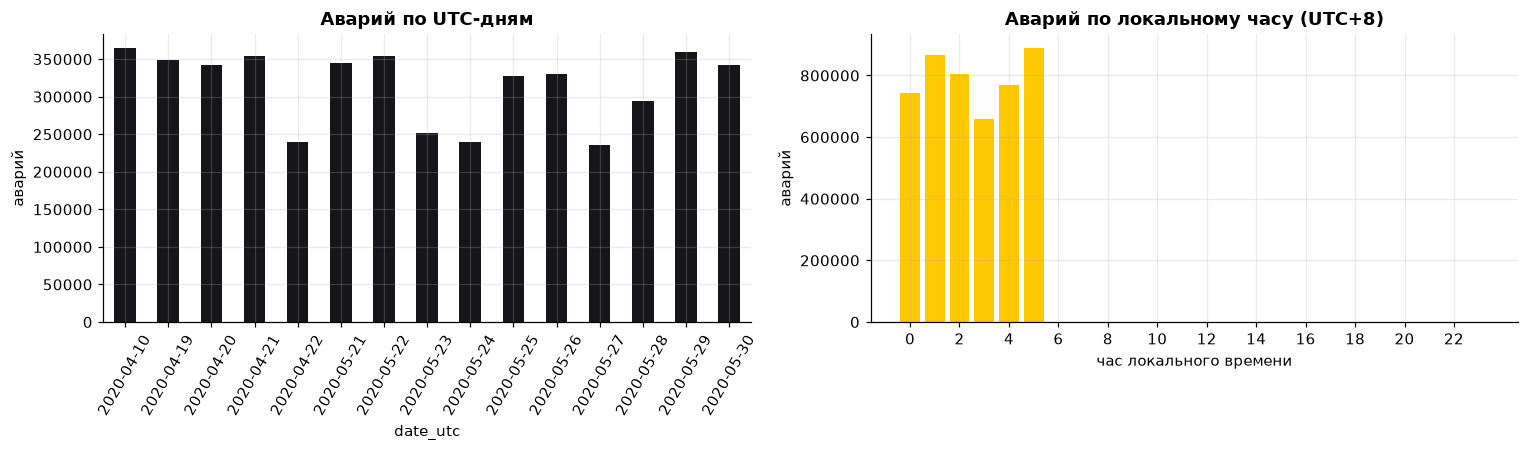

Часы с ненулевой активностью: [0, 1, 2, 3, 4, 5, 6]
Доля аварий в 00:00–05:59 локального времени: 99.999979%
Событий в 06:00 локального времени: 1


In [19]:
alarms["date_utc"] = alarms["ts"].dt.date
alarms["local_ts"] = alarms["ts"] + pd.Timedelta(hours=8)
alarms["local_hour"] = alarms["local_ts"].dt.hour
alarms["local_date"] = alarms["local_ts"].dt.date

day_counts = alarms.groupby("date_utc").size()
print("UTC-дни:", len(day_counts), "| локальные дни:", alarms["local_date"].nunique())
print("Диапазон локального времени:", alarms["local_ts"].min(), "—", alarms["local_ts"].max())
display(day_counts.to_frame("alarms").assign(
    share=lambda d: (d["alarms"] / d["alarms"].sum()).round(4)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
day_counts.plot(kind="bar", ax=axes[0], color=C_MAIN)
axes[0].set_title("Аварий по UTC-дням")
axes[0].set_ylabel("аварий")
axes[0].tick_params(axis="x", rotation=60)

hour_counts = alarms.groupby("local_hour").size().reindex(range(24), fill_value=0)
axes[1].bar(hour_counts.index, hour_counts.values, color=C_ALT)
axes[1].set_title("Аварий по локальному часу (UTC+8)")
axes[1].set_xlabel("час локального времени")
axes[1].set_ylabel("аварий")
axes[1].set_xticks(range(0, 24, 2))
fig.tight_layout()
plt.show()

print("Часы с ненулевой активностью:", sorted(hour_counts[hour_counts > 0].index.tolist()))
print(f"Доля аварий в 00:00–05:59 локального времени: "
      f"{hour_counts.loc[0:5].sum() / hour_counts.sum():.6%}")
print("Событий в 06:00 локального времени:", int(hour_counts.get(6, 0)))

**Что видим.** Покрытие — не 24 часа, а 6-часовое ночное окно (единичные события попадают на границу 06:00). В графике по UTC видны «разрывы»: 11–18 апреля и 24 апреля–21 мая аварий нет. Это два блока наблюдений: апрельский (11, 20–23) и майский (22–31). Для сравнения «до/после» и для holdout это означает, что май отделён от апреля почти месяцем, а не следующим днём.

Дополнительно проверим матрицу «дата × локальный час»: она показывает и пропуски, и стабильность ночного окна.

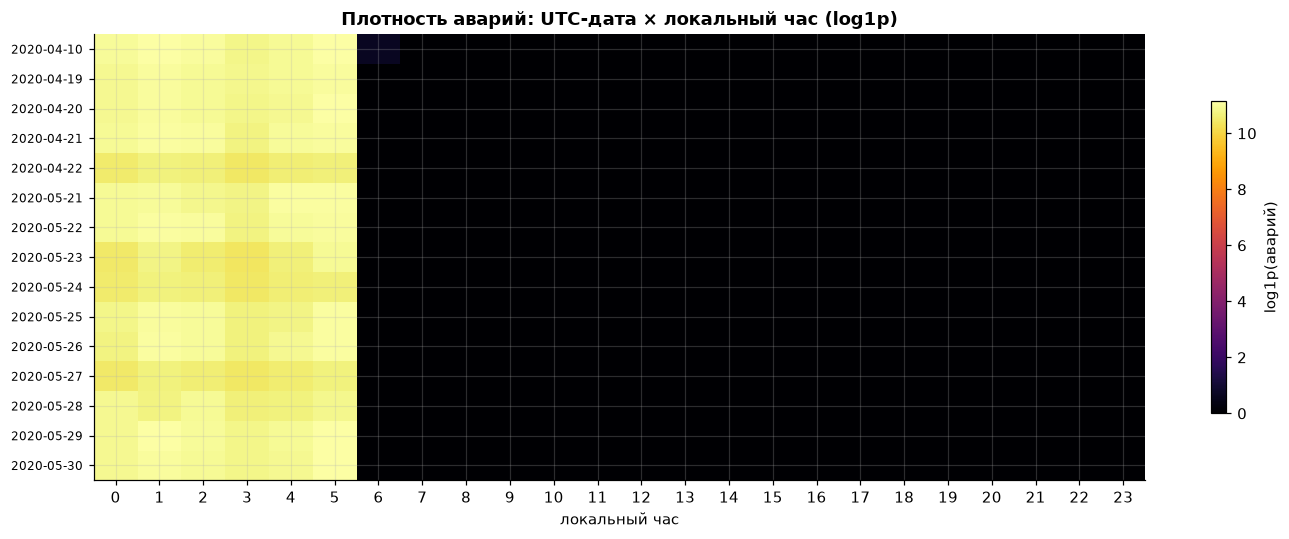

In [34]:
heat = (alarms.groupby(["date_utc", "local_hour"]).size()
        .unstack(fill_value=0)
        .reindex(columns=range(24), fill_value=0))
fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(np.log1p(heat.values), aspect="auto", cmap="inferno")
ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels([str(d) for d in heat.index], fontsize=8)
ax.set_xlabel("локальный час")
ax.set_title("Плотность аварий: UTC-дата × локальный час (log1p)")
fig.colorbar(im, ax=ax, shrink=0.7, label="log1p(аварий)")
fig.tight_layout()
plt.show()

## 5. Одномерный EDA: кто и что генерирует аварию

Цель раздела — понять структуру потока до корреляций. Смотрим:

- долю слоёв (`integration`);
- концентрацию по `system` и `alert_group` (закон Парето);
- распределение по узлам;
- сколько устройств стоит за одной группой.

Это отвечает на RQ1 и частично RQ2: если 90% потока — один тип события, корреляции будут измерять именно его, а не межсистемные зависимости.

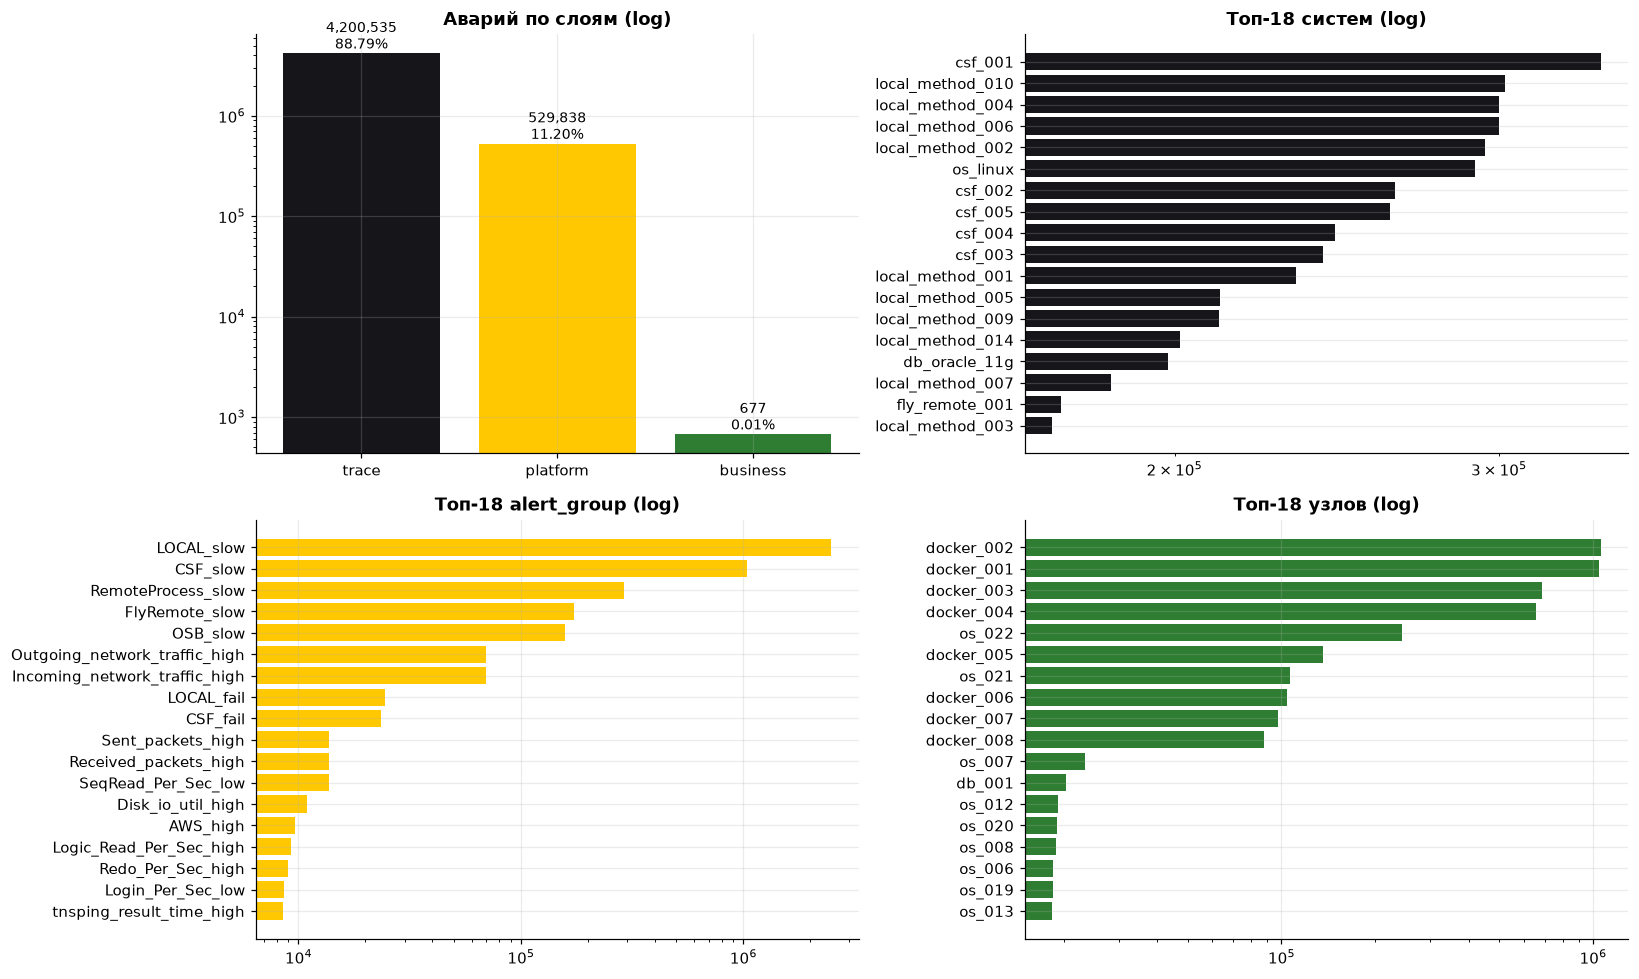

,integration,share
integration,,
trace,4200535,0.8879
platform,529838,0.1120
business,677,0.0001


Уникальных system: 27; alert_group: 158; node: 57


In [35]:
integ = alarms["integration"].value_counts()
system_counts = alarms["system"].value_counts()
group_counts = alarms["alert_group"].value_counts()
node_counts = alarms["node"].value_counts()

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

axes[0, 0].bar(integ.index, integ.values, color=[C_MAIN, C_ALT, C_OK])
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Аварий по слоям (log)")
for i, v in enumerate(integ.values):
    axes[0, 0].text(i, v, f"{v:,}\n{v/len(alarms):.2%}", ha="center", va="bottom", fontsize=9)

top_sys = system_counts.head(18).iloc[::-1]
axes[0, 1].barh(top_sys.index, top_sys.values, color=C_MAIN)
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("Топ-18 систем (log)")

top_ag = group_counts.head(18).iloc[::-1]
axes[1, 0].barh(top_ag.index, top_ag.values, color=C_ALT)
axes[1, 0].set_xscale("log")
axes[1, 0].set_title("Топ-18 alert_group (log)")

top_node = node_counts.head(18).iloc[::-1]
axes[1, 1].barh(top_node.index, top_node.values, color=C_OK)
axes[1, 1].set_xscale("log")
axes[1, 1].set_title("Топ-18 узлов (log)")

fig.tight_layout()
plt.show()

display(pd.DataFrame({
    "integration": integ,
    "share": (integ / len(alarms)).round(4),
}))
print(f"Уникальных system: {alarms['system'].nunique()}; "
      f"alert_group: {alarms['alert_group'].nunique()}; node: {alarms['node'].nunique()}")

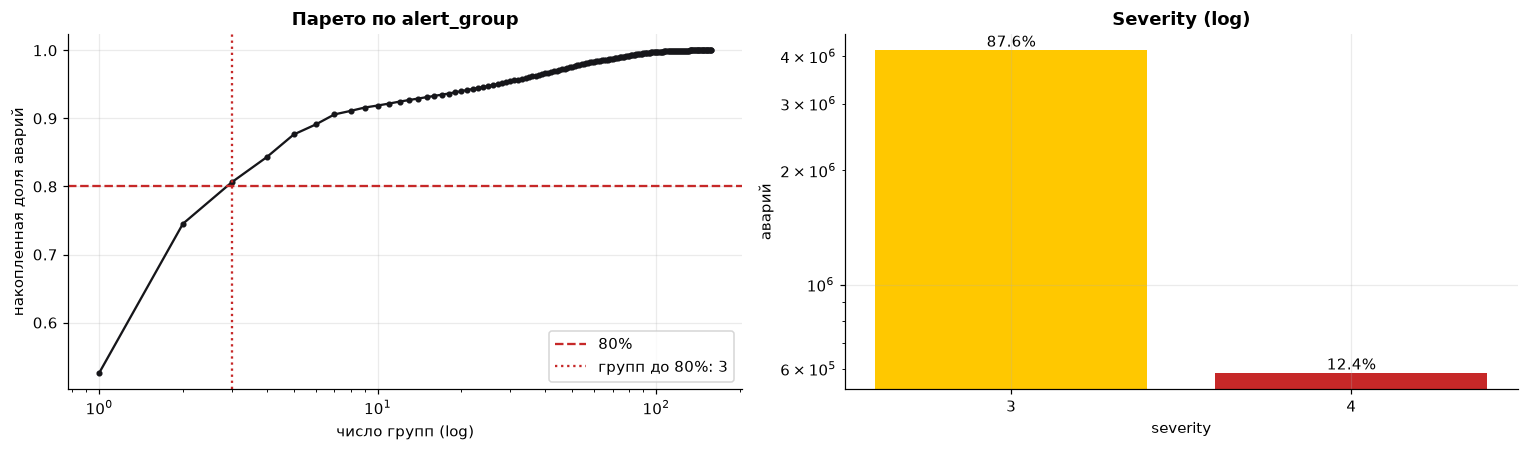

Топ-5 alert_group покрывают 87.6% потока
Топ-10 alert_group покрывают 91.9% потока


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

g = group_counts.sort_values(ascending=False)
cum = g.cumsum() / g.sum()
axes[0].plot(np.arange(1, len(g) + 1), cum.values, marker=".", color=C_MAIN)
axes[0].axhline(0.8, ls="--", color=C_WARN, label="80%")
n80 = int((cum < 0.8).sum() + 1)
axes[0].axvline(n80, ls=":", color=C_WARN, label=f"групп до 80%: {n80}")
axes[0].set_xscale("log")
axes[0].set_xlabel("число групп (log)")
axes[0].set_ylabel("накопленная доля аварий")
axes[0].set_title("Парето по alert_group")
axes[0].legend()

sev = alarms["severity"].value_counts().sort_index()
axes[1].bar(sev.index.astype(str), sev.values, color=[C_ALT, C_WARN])
axes[1].set_yscale("log")
axes[1].set_title("Severity (log)")
axes[1].set_xlabel("severity")
axes[1].set_ylabel("аварий")
for i, v in enumerate(sev.values):
    axes[1].text(i, v, f"{v/len(alarms):.1%}", ha="center", va="bottom")

fig.tight_layout()
plt.show()

print(f"Топ-5 alert_group покрывают {group_counts.head(5).sum()/len(alarms):.1%} потока")
print(f"Топ-10 alert_group покрывают {group_counts.head(10).sum()/len(alarms):.1%} потока")

**Интерпретация.** Потоком управляют несколько трейсовых групп: `LOCAL_slow` (2,49 млн), `CSF_slow` (1,04 млн), `RemoteProcess_slow`, `FlyRemote_slow`, `OSB_slow`. Это не «аварии оборудования» в классическом смысле, а события медленных вызовов. Платформенные метрики (`CPU`, сеть, диск, Oracle) на два порядка малочисленнее. Бизнес-слой (`esb`) практически отсутствует — 677 событий.

Отсюда первый методический вывод: **если фильтровать по числу устройств, трейсовые ряды исчезнут**, потому что они агрегированы по сервису и в апрельском train исполняются на 1–4 `cmdb_id`. Именно это произойдёт в разделе 6.

### 5.1 Сколько устройств стоит за группой

`min_devices` — ключевой фильтр методики: корреляция на одном устройстве может быть устойчивой, но она не доказывает межобъектную зависимость. Посмотрим распределение числа узлов по группам.

,groups
devices,
1,11
2,6
3,7
4,36
5,5
6,3
7,9
8,8
9,10


Групп всего: 190; с одним устройством: 11 (5.79%)


,groups,devices_median,devices_max,events_median
integration,,,,
business,2,1.0,1,338.5
platform,147,12.0,22,1855.0
trace,41,4.0,7,30567.0


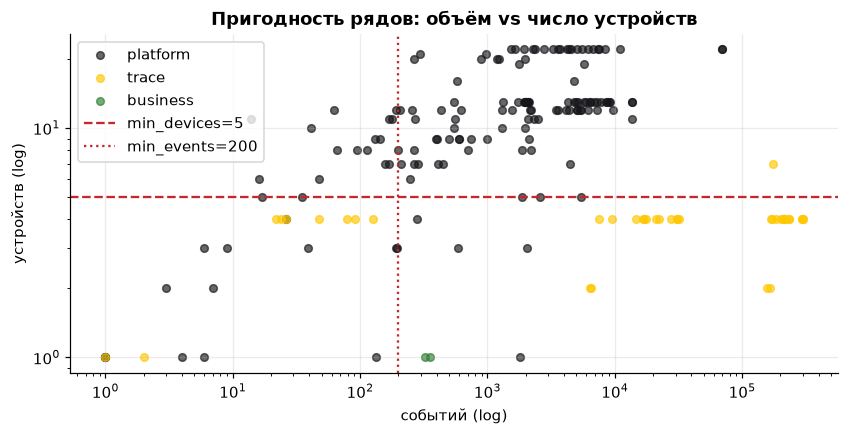

In [37]:
grp = (alarms.groupby(GROUP_KEY)
       .agg(events=("ts", "size"),
            devices=("node", "nunique"),
            days=("date_utc", "nunique"),
            groups=("alert_group", "size"))
       .reset_index())
grp["events_per_day"] = (grp["events"] / grp["days"].clip(lower=1)).round(1)

display(grp["devices"].value_counts().sort_index().to_frame("groups"))
print(f"Групп всего: {len(grp)}; с одним устройством: {(grp.devices == 1).sum()} "
      f"({(grp.devices == 1).mean():.2%})")
display(grp.groupby("integration").agg(groups=("system", "size"),
                                       devices_median=("devices", "median"),
                                       devices_max=("devices", "max"),
                                       events_median=("events", "median")).round(2))

fig, ax = plt.subplots(figsize=(9, 4))
for integ_name, color in zip(["platform", "trace", "business"], [C_MAIN, C_ALT, C_OK]):
    sub = grp[grp.integration == integ_name]
    if not sub.empty:
        ax.scatter(sub["events"].clip(lower=1), sub["devices"].clip(lower=1),
                   s=25, alpha=0.65, label=integ_name, color=color)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axhline(CFG.min_devices, ls="--", color=C_WARN, label=f"min_devices={CFG.min_devices}")
ax.axvline(CFG.min_events, ls=":", color=C_WARN, label=f"min_events={CFG.min_events}")
ax.set_xlabel("событий (log)")
ax.set_ylabel("устройств (log)")
ax.set_title("Пригодность рядов: объём vs число устройств")
ax.legend()
plt.show()

## 6. Бининг и фильтры: сколько рядов доходит до корреляций

Движок работает не с отдельными авариями, а с временными рядами:

- **бин** = 5 минут (компромисс: часы коллекторов расходятся до ±5 минут; при 1 минуте событие размазывается по бинам);
- **ряд** = `(integration, system, alert_group)`; регион отбрасывается, потому что в датасете он пустой, а в реальном Netcool он не должен дробить одну зависимость на города;
- **фильтры**: `min_events=200`, `min_bins=100`, `min_devices=5`.

Сначала строим матрицу `бины × ряды` только на апреле — это train-период сохранённого прогона. Затем показываем «водопад» отсева: сколько групп было, сколько прошло объём и сколько прошло устройство.

Апрель: строк 1,649,320; матрица 3,528 бинов × 90 рядов
Плотность матрицы: 8.6250% (доля ненулевых ячеек)
Диапазон grid: 2020-04-10 16:00:00 — 2020-04-22 21:55:00


,groups,after_volume,final,devices_median,devices_max
integration,,,,,
business,2.0,0.0,0.0,1.0,1.0
platform,143.0,93.0,90.0,12.0,22.0
trace,41.0,27.0,0.0,4.0,4.0
TOTAL,186.0,120.0,90.0,17.0,27.0


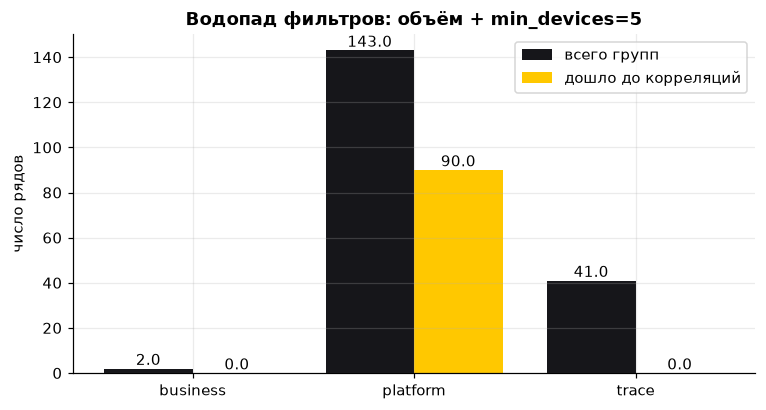

In [51]:
april = alarms[alarms["ts"].dt.month == 4].copy()
b = build_bins(april, CFG)
M = b.M
density = float((M > 0).mean()) if M.size else 0.0

print(f"Апрель: строк {len(april):,}; матрица {M.shape[0]:,} бинов × {M.shape[1]} рядов")
print(f"Плотность матрицы: {density:.4%} (доля ненулевых ячеек)")
print(f"Диапазон grid: {b.grid[0]} — {b.grid[-1]}")

# Водопад отсева по слоям: объёмные фильтры и min_devices считаем независимо,
# чтобы было видно, какой именно фильтр убивает слой.
d = april[april["severity"] > 0].copy()
d["bucket"] = d["ts"].dt.floor(f"{CFG.bin_min}min")
agg = d.groupby(GROUP_KEY + ["bucket"], sort=False).size().reset_index(name="cnt")
ev = agg.groupby(GROUP_KEY)["cnt"].sum()
bn = agg.groupby(GROUP_KEY)["bucket"].nunique()
dv = d.groupby(GROUP_KEY)["node"].nunique()
stats = pd.DataFrame({"events": ev, "bins": bn, "devices": dv}).reset_index()
stats["pass_volume"] = (stats["events"] >= CFG.min_events) & (stats["bins"] >= CFG.min_bins)
stats["pass_device"] = stats["pass_volume"] & (stats["devices"] >= CFG.min_devices)
waterfall = (stats.groupby("integration")
             .agg(groups=("system", "size"),
                  after_volume=("pass_volume", "sum"),
                  final=("pass_device", "sum"),
                  devices_median=("devices", "median"),
                  devices_max=("devices", "max"))
             .astype({"groups": int, "after_volume": int, "final": int}))
waterfall.loc["TOTAL"] = waterfall.sum(numeric_only=True)
display(waterfall)

fig, ax = plt.subplots(figsize=(8, 4))
wf = waterfall.drop(index="TOTAL")
x = np.arange(len(wf))
ax.bar(x - 0.2, wf["groups"], width=0.4, label="всего групп", color=C_MAIN)
ax.bar(x + 0.2, wf["final"], width=0.4, label="дошло до корреляций", color=C_ALT)
ax.set_xticks(x); ax.set_xticklabels(wf.index)
ax.set_ylabel("число рядов")
ax.set_title("Водопад фильтров: объём + min_devices=5")
ax.legend()
for i, (a, z) in enumerate(zip(wf["groups"], wf["final"])):
    ax.text(i - 0.2, a, str(a), ha="center", va="bottom")
    ax.text(i + 0.2, z, str(z), ha="center", va="bottom")
plt.show()

**Ключевой результат.** Объёмный фильтр проходят 27 трейсовых групп, но `min_devices=5` отсекает **все** (в апреле у них максимум 4 устройства). Бизнес-слой не проходит объём (2 группы, по одному устройству). В итоге из 186 апрельских групп остаётся 90 — и все они `platform`.

Это не «баг», а несовместимость параметра с гранулярностью источника: в Netcool одна авария может приходить с десятков узлов, в AIOps 2020 трейс-сервис в апреле представлен 1–4 `cmdb_id`. Для исследовательского вывода важно: **граф бабочки в текущей конфигурации — это граф платформенных метрик, а не всего мониторинга**. Во всём потоке есть одна trace-группа (`FlyRemote_slow`) с 7 устройствами, но она появляется только в мае и в детекцию не попадает.

### 6.1 Duty cycle и хабы

После фильтра объёма проверяем ещё два контроля:

- `duty > 0.5` — «вечно горящий» ряд (вотчдог, heartbeat);
- степень связности `> 60` — хаб, который коррелирует со всем подряд.

Степень считаем по числу пар с `|corr| ≥ 0.35` после снятия общего фактора.

,series,duty_median,duty_max,degree_median,degree_max
integration,,,,,
platform,90,0.097,0.102,5.0,40


«Вечно горящих» (duty > 0.5): 0
Хабов (degree > 60): 0
Максимальная степень: 40


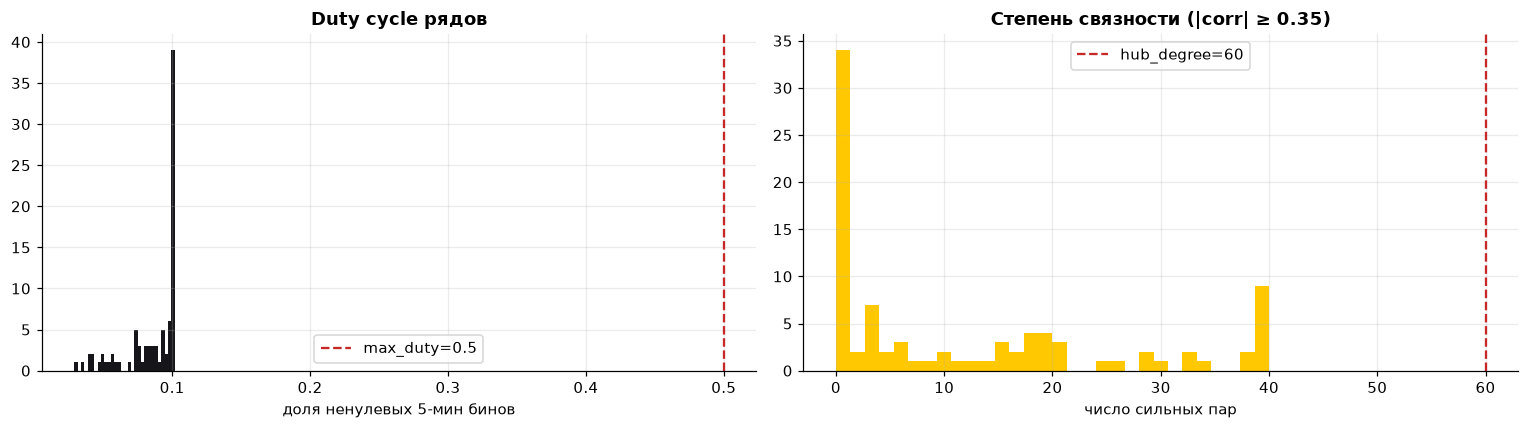

,key,integration,system,alert_group,events,devices,duty,degree
69,"(platform, os_linux, Incoming_network_traffic_...",platform,os_linux,Incoming_network_traffic_high,23697,22,0.102,40
30,"(platform, db_oracle_11g, SeqRead_Per_Sec_low)",platform,db_oracle_11g,SeqRead_Per_Sec_low,4578,10,0.102,40
76,"(platform, os_linux, Outgoing_network_traffic_...",platform,os_linux,Outgoing_network_traffic_high,23690,22,0.102,40
21,"(platform, db_oracle_11g, New_Tbs_Used_Pct_high)",platform,db_oracle_11g,New_Tbs_Used_Pct_high,1807,5,0.050,39
13,"(platform, db_oracle_11g, Logic_Read_Per_Sec_h...",platform,db_oracle_11g,Logic_Read_Per_Sec_high,2983,13,0.101,39
88,"(platform, os_linux, Sent_packets_high)",platform,os_linux,Sent_packets_high,4647,13,0.101,39
83,"(platform, os_linux, Received_packets_high)",platform,os_linux,Received_packets_high,4645,13,0.102,39
20,"(platform, db_oracle_11g, New_Tbs_Free_Gb_high)",platform,db_oracle_11g,New_Tbs_Free_Gb_high,2119,12,0.050,39
10,"(platform, db_oracle_11g, Exec_Per_Sec_high)",platform,db_oracle_11g,Exec_Per_Sec_high,2207,13,0.095,39
2,"(platform, db_oracle_11g, AIOS_high)",platform,db_oracle_11g,AIOS_high,862,10,0.058,38


In [39]:
X = transform_matrix(M, CFG.transform)
Z, ok = zscore(X)
R = remove_common_factor(X, ok)
Rz, okR = zscore(R)
best, best_lag = best_lag_matrix(Rz, CFG.lags)

duty = (M > 0).mean(0)
strong = (np.abs(best) >= CFG.min_abs_corr) & okR[:, None] & okR[None, :]
degree = strong.sum(1) - 1

series_quality = pd.DataFrame({
    "key": b.keys,
    "integration": [k[0] for k in b.keys],
    "system": [k[1] for k in b.keys],
    "alert_group": [k[2] for k in b.keys],
    "events": [b.events[k] for k in b.keys],
    "devices": [len(b.device_sets.get(k[:3], ())) for k in b.keys],
    "duty": duty,
    "degree": degree,
})
display(series_quality.groupby("integration").agg(
    series=("key", "size"), duty_median=("duty", "median"),
    duty_max=("duty", "max"), degree_median=("degree", "median"),
    degree_max=("degree", "max")).round(3))

print(f"«Вечно горящих» (duty > {CFG.max_duty}): {(duty > CFG.max_duty).sum()}")
print(f"Хабов (degree > {CFG.hub_degree}): {(degree > CFG.hub_degree).sum()}")
print(f"Максимальная степень: {degree.max()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(duty, bins=30, color=C_MAIN)
axes[0].axvline(CFG.max_duty, ls="--", color=C_WARN, label=f"max_duty={CFG.max_duty}")
axes[0].set_title("Duty cycle рядов")
axes[0].set_xlabel("доля ненулевых 5-мин бинов")
axes[0].legend()

axes[1].hist(degree, bins=30, color=C_ALT)
axes[1].axvline(CFG.hub_degree, ls="--", color=C_WARN, label=f"hub_degree={CFG.hub_degree}")
axes[1].set_title("Степень связности (|corr| ≥ 0.35)")
axes[1].set_xlabel("число сильных пар")
axes[1].legend()
fig.tight_layout()
plt.show()

display(series_quality.sort_values("degree", ascending=False).head(12).round(3))

**Что видим.** В платформенном слое нет ни «вечно горящих», ни хабов по заданным порогам: максимальная степень ~40 при пороге 60, duty ≤ ~0.12. Значит, фильтры не режут полезные ряды. Но высокая степень (30–40) у сетевых и Oracle-метрик говорит о том, что внутри платформы много сильно связанных метрик; межсистемность (`system` различается) остаётся главным ограничителем.

## 7. Корреляции и лаги

Как считается связь:

1. ряд логарифмируется (`log1p`) и z-нормируется;
2. вычитается общий фактор — регрессия на суммарную активность всех рядов в бине (суточный профиль, штормы);
3. для каждой пары перебираются лаги от −12 до +12 бинов (±1 час), выбирается лаг с максимальным `|corr|`;
4. `corr0` — корреляция при нулевом лаге; `lead = |corr| − |corr0|` показывает, даёт ли сдвиг выигрыш.

Посмотрим на топ-пару из сохранённого прогона: `db_oracle_11g|AIOS_high` ↔ `os_linux|Sent_packets_high`.

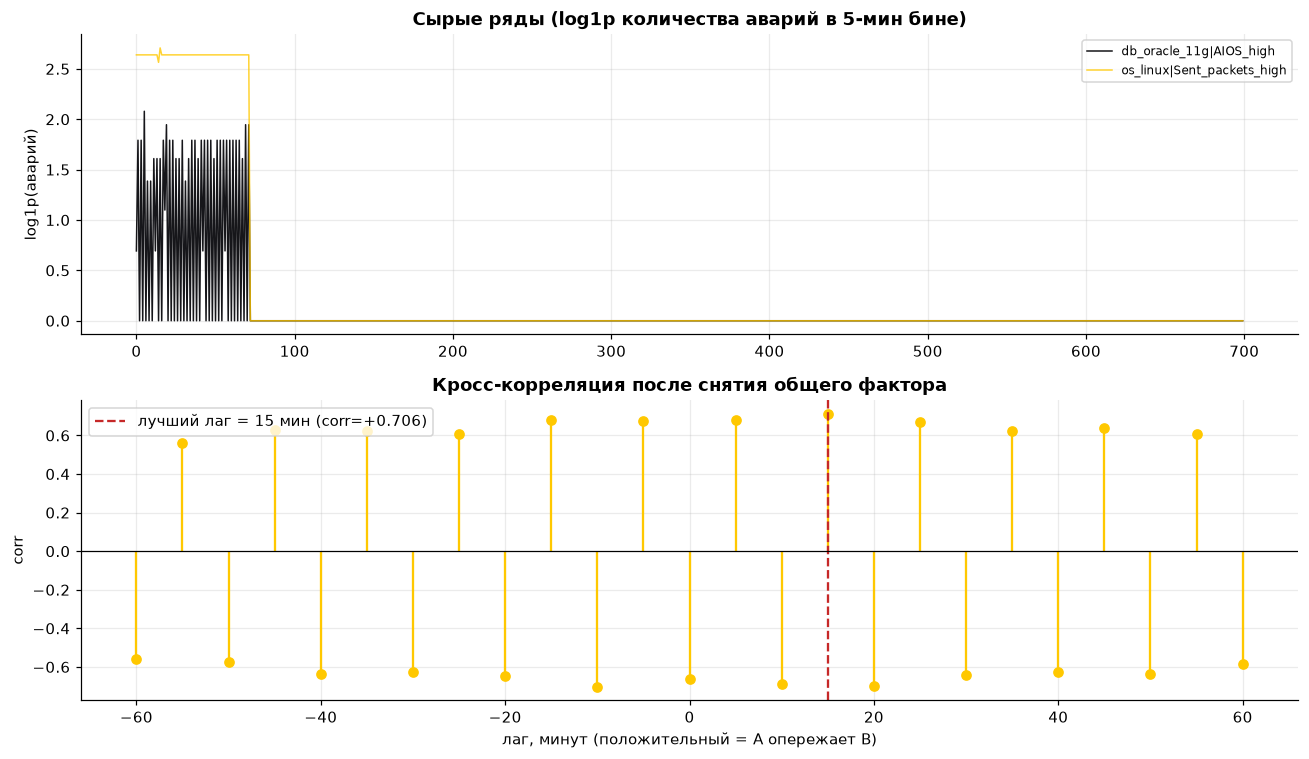

('platform', 'db_oracle_11g', 'AIOS_high') <-> ('platform', 'os_linux', 'Sent_packets_high')
corr=+0.7058 при лаге 15 мин; corr0=-0.6646; lead=+0.0413; support=203 бинов


In [45]:
top_pair = saved_pairs[0]
ka, kb = tuple(top_pair["key_a"]), tuple(top_pair["key_b"])
ia, ib = b.keys.index(ka), b.keys.index(kb)

raw_a, raw_b = M[:, ia], M[:, ib]
lags = np.arange(-CFG.lags, CFG.lags + 1)
ccf = []
for lag in lags:
    if lag >= 0:
        x, y = Rz[: len(Rz) - lag, ia], Rz[lag:, ib]
    else:
        x, y = Rz[-lag:, ia], Rz[: len(Rz) + lag, ib]
    ccf.append(float(np.corrcoef(x, y)[0, 1]))
ccf = np.array(ccf)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
n_show = min(700, len(raw_a))
axes[0].plot(np.arange(n_show), np.log1p(raw_a[:n_show]), lw=1, 
             color=C_MAIN, label=f"{ka[1]}|{ka[2]}")

axes[0].plot(np.arange(n_show), np.log1p(raw_b[:n_show]), lw=1, alpha=0.8, 
             color=C_ALT, label=f"{kb[1]}|{kb[2]}")
axes[0].set_title("Сырые ряды (log1p количества аварий в 5-мин бине)")
axes[0].set_ylabel("log1p(аварий)")
axes[0].legend(fontsize=8)

axes[1].stem(lags * CFG.bin_min, ccf, linefmt=C_ALT, basefmt=" ")
axes[1].axvline(top_pair["lag_min"], color=C_WARN, ls="--",
                label=f"лучший лаг = {top_pair['lag_min']} мин (corr={top_pair['corr']:+.3f})")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Кросс-корреляция после снятия общего фактора")
axes[1].set_xlabel("лаг, минут (положительный = A опережает B)")
axes[1].set_ylabel("corr")
axes[1].legend()
fig.tight_layout()
plt.show()

print(f"{ka} <-> {kb}")
print(f"corr={top_pair['corr']:+.4f} при лаге {top_pair['lag_min']} мин; "
      f"corr0={top_pair['corr0']:+.4f}; lead={top_pair['lead']:+.4f}; "
      f"support={top_pair['support']} бинов")

График показывает важную вещь: **знак корреляции при нулевом лаге и при лучшем лаге может различаться**. У топ-пары `corr0 = −0,665`, а на лаге +15 минут `corr = +0,706`. Это означает, что без перебора лагов пара выглядела бы обратной связью или не прошла бы порог. Именно поэтому lag-анализ обязателен, а `lead` — информативный признак.

Дальше — распределения по всем 258 парам.

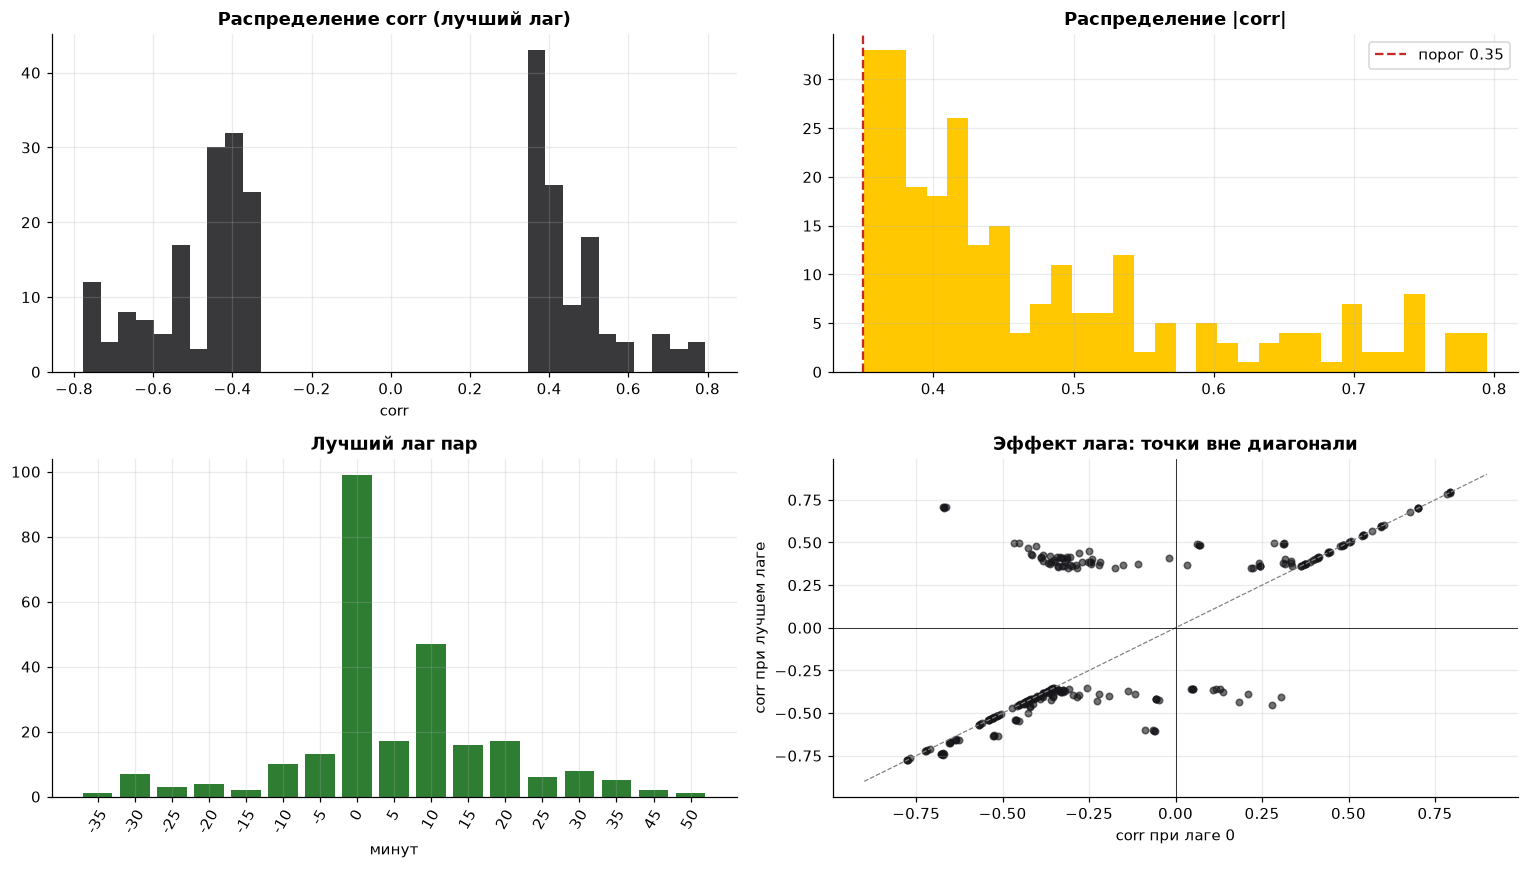

,corr,corr0,lead,support,days_frac,score
count,258.000,258.000,258.000,258.000,258.000,258.000
mean,-0.063,-0.176,0.072,291.527,0.868,0.239
std,0.486,0.402,0.112,76.203,0.156,0.106
min,-0.778,-0.778,0.000,65.000,0.600,0.056
25%,-0.446,-0.437,0.000,203.000,0.800,0.154
50%,-0.361,-0.336,0.024,329.000,1.000,0.223
75%,0.408,0.134,0.092,357.000,1.000,0.298
max,0.795,0.795,0.542,359.000,1.000,0.706


Пар с lag=0: 99 из 258 (38.4%)
Пар с ненулевым лагом: 159
Пар, где |corr| > |corr0| более чем на 0.2: 31


In [46]:
pdf = pd.DataFrame(saved_pairs)
pdf["abs_corr"] = pdf["corr"].abs()
pdf["days_frac"] = pdf["days_ok"] / pdf["days_total"].clip(lower=1)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].hist(pdf["corr"], bins=35, color=C_MAIN, alpha=0.85)
axes[0, 0].set_title("Распределение corr (лучший лаг)")
axes[0, 0].set_xlabel("corr")

axes[0, 1].hist(pdf["abs_corr"], bins=30, color=C_ALT)
axes[0, 1].axvline(CFG.min_abs_corr, ls="--", color=C_WARN, label=f"порог {CFG.min_abs_corr}")
axes[0, 1].set_title("Распределение |corr|")
axes[0, 1].legend()

lag_counts = pdf["lag_min"].value_counts().sort_index()
axes[1, 0].bar(lag_counts.index.astype(str), lag_counts.values, color=C_OK)
axes[1, 0].set_title("Лучший лаг пар")
axes[1, 0].set_xlabel("минут")
axes[1, 0].tick_params(axis="x", rotation=60)

axes[1, 1].scatter(pdf["corr0"], pdf["corr"], s=18, alpha=0.6, color=C_MAIN)
lim = [-0.9, 0.9]
axes[1, 1].plot(lim, lim, ls="--", color="gray", lw=0.8)
axes[1, 1].axhline(0, color="black", lw=0.5)
axes[1, 1].axvline(0, color="black", lw=0.5)
axes[1, 1].set_xlabel("corr при лаге 0")
axes[1, 1].set_ylabel("corr при лучшем лаге")
axes[1, 1].set_title("Эффект лага: точки вне диагонали")

fig.tight_layout()
plt.show()

display(pdf[["corr", "corr0", "lead", "support", "days_frac", "score"]].describe().round(3))
print(f"Пар с lag=0: {(pdf['lag_bins'] == 0).sum()} из {len(pdf)} "
      f"({(pdf['lag_bins'] == 0).mean():.1%})")
print(f"Пар с ненулевым лагом: {(pdf['lag_bins'] != 0).sum()}")
print(f"Пар, где |corr| > |corr0| более чем на 0.2: {(pdf['lead'] > 0.2).sum()}")

**Интерпретация.** Большинство пар (99 из 258) имеют лаг 0 — это синхронные платформенные метрики. Ненулевой лаг есть у 159 пар, но выраженный выигрыш (`lead > 0.2`) — только у 31. Порог `|corr| ≥ 0.35` проходит 258 пар после всех контролей; это не «топ-10», а довольно широкий слой кандидатов, который нужно ранжировать.

## 8. Результаты сохранённого прогона

Полный прогон: train — апрель, holdout — май, `rows_series=90`, `bins=3528`, `pairs_found=258`, `lead_pairs=31`. Ниже — структура находок, а не только топ-таблица.

In [14]:
print("info:", json.dumps(saved_info, ensure_ascii=False, indent=2))
display(pdf["class"].value_counts().to_frame("pairs"))

overlap = pd.json_normalize(pdf["overlap"])
shared = pd.json_normalize(pdf["shared_unshared"])
print("Вердикты по пересечению устройств:")
display(overlap["verdict"].value_counts().to_frame("pairs"))
display(overlap[["devices_a", "devices_b", "common", "overlap_frac"]].describe().round(3))
print("Вердикты shared/unshared:")
display(shared["verdict"].value_counts().to_frame("pairs"))

info: {
  "months": [
    "2020-04",
    "2020-05"
  ],
  "train_months": [
    "2020-04"
  ],
  "holdout_months": [
    "2020-05"
  ],
  "rows_series": 90,
  "bins": 3528,
  "dropped_volume": 96,
  "dropped_min_devices": 30,
  "pairs_found": 258,
  "lead_pairs": 31
}


,pairs
class,
BUTTERFLY_CANDIDATE,258


Вердикты по пересечению устройств:


,pairs
verdict,
NO_OVERLAP,258


,devices_a,devices_b,common,overlap_frac
count,258.000,258.000,258.0,258.0
mean,11.690,18.690,0.0,0.0
std,2.206,4.254,0.0,0.0
min,5.000,5.000,0.0,0.0
25%,11.000,13.000,0.0,0.0
50%,13.000,22.000,0.0,0.0
75%,13.000,22.000,0.0,0.0
max,13.000,22.000,0.0,0.0


Вердикты shared/unshared:


,pairs
verdict,
NO_COMMON_DEVICES,258


In [15]:
def key_label(k):
    return f"{k[0]} | {k[1]} | {k[2]}"

top_view = pdf.sort_values("score", ascending=False).head(15).copy()
top_view["leader"] = [
    key_label(p["key_a"] if p["lag_bins"] >= 0 else p["key_b"]) for _, p in top_view.iterrows()]
top_view["follower"] = [
    key_label(p["key_b"] if p["lag_bins"] >= 0 else p["key_a"]) for _, p in top_view.iterrows()]
display(top_view[["leader", "follower", "corr", "corr0", "lag_min", "support",
                  "days_ok", "days_total", "month_stable", "score"]]
        .rename(columns={"corr": "corr_best", "corr0": "corr_lag0"})
        .round(3))

system_pairs = pdf.apply(
    lambda p: pd.Series({
        "a": p["key_a"][1], "b": p["key_b"][1],
        "lag": p["lag_min"], "class": p["class"], "score": p["score"]}), axis=1)
matrix = (system_pairs.groupby(["a", "b"]).size().unstack(fill_value=0))
display(matrix)
print("Лидер → ведомый (по знаку лага):")
leader_counts = pd.Series([
    f"{p['key_a'][1] if p['lag_bins'] >= 0 else p['key_b'][1]} → "
    f"{p['key_b'][1] if p['lag_bins'] >= 0 else p['key_a'][1]}"
    for p in saved_pairs]).value_counts()
display(leader_counts.to_frame("pairs"))

,leader,follower,corr_best,corr_lag0,lag_min,support,days_ok,days_total,month_stable,score
0,platform | db_oracle_11g | AIOS_high,platform | os_linux | Sent_packets_high,0.706,-0.665,15,203,5,5,True,0.706
1,platform | db_oracle_11g | AIOS_high,platform | os_linux | Outgoing_network_traffic...,0.706,-0.672,15,203,5,5,True,0.706
2,platform | db_oracle_11g | AIOS_high,platform | os_linux | Incoming_network_traffic...,0.705,-0.671,15,203,5,5,True,0.705
3,platform | db_oracle_11g | Physical_Read_Per_S...,platform | os_linux | Page_po_high,0.495,-0.468,5,281,13,13,True,0.495
4,platform | db_oracle_11g | DbTime_high,platform | os_linux | Page_po_high,0.495,-0.453,25,306,5,5,True,0.495
5,platform | db_oracle_11g | Logic_Read_Per_Sec_...,platform | os_linux | Page_po_high,0.469,-0.428,5,334,5,5,True,0.469
6,platform | db_oracle_11g | Logic_Read_Per_Sec_...,platform | os_linux | CPU_iowait_time_high,0.438,-0.280,5,357,5,5,True,0.438
7,platform | db_oracle_11g | AIOS_high,platform | os_linux | Received_packets_high,0.703,-0.669,15,203,8,13,True,0.433
8,platform | db_oracle_11g | AIOS_high,platform | os_linux | Disk_io_util_high,0.425,-0.416,5,203,5,5,True,0.425
9,platform | db_oracle_11g | DbTime_high,platform | os_linux | Disk_await_high,0.417,-0.314,5,329,5,5,True,0.417


b,mw_redis,os_linux
a,,
db_oracle_11g,21,228
mw_redis,0,9


Лидер → ведомый (по знаку лага):


,pairs
db_oracle_11g → os_linux,193
os_linux → db_oracle_11g,35
db_oracle_11g → mw_redis,17
mw_redis → os_linux,8
mw_redis → db_oracle_11g,4
os_linux → mw_redis,1


**Почему все 258 пар — `BUTTERFLY_CANDIDATE`.** Вердикт выносится по пересечению множеств устройств. В AIOps 2020 `db_*` и `os_*` — это разные `cmdb_id`; пересечения нет ни у одной пары (`common=0` во всех 258). Поэтому `shared_unshared_corr` не может найти общие устройства и возвращает `NO_COMMON_DEVICES`, а `finalize_pairs` ставит `BUTTERFLY_CANDIDATE`.

Это важный вывод для дизайна: **тест на дублирование работает только там, где разные системы действительно видят один и тот же узел**. В платформенном слое этого не происходит. Значит:

- класс `BUTTERFLY_CANDIDATE` здесь означает «нет пересечения устройств», а не «доказана скрытая зависимость»;
- для реального Netcool нужен второй идентификатор (`node_alias`), чтобы связывать разные `Node` одной сущности;
- для датасета AIOps 2020 разумнее валидировать пары по ground truth и по физическому смыслу метрик, а не только по device overlap.

### 8.1 Устойчивость и ранг

Ранг пары: `score = |corr| · (days_ok/days_total) · regions_frac · (1 если месяц-стабильна, 0.5 иначе)`. Регион в датасете пустой, поэтому `regions_frac` фактически вырожден (0 или 1 на единственном «регионе»). Смотрим на устойчивость по дням и на holdout.

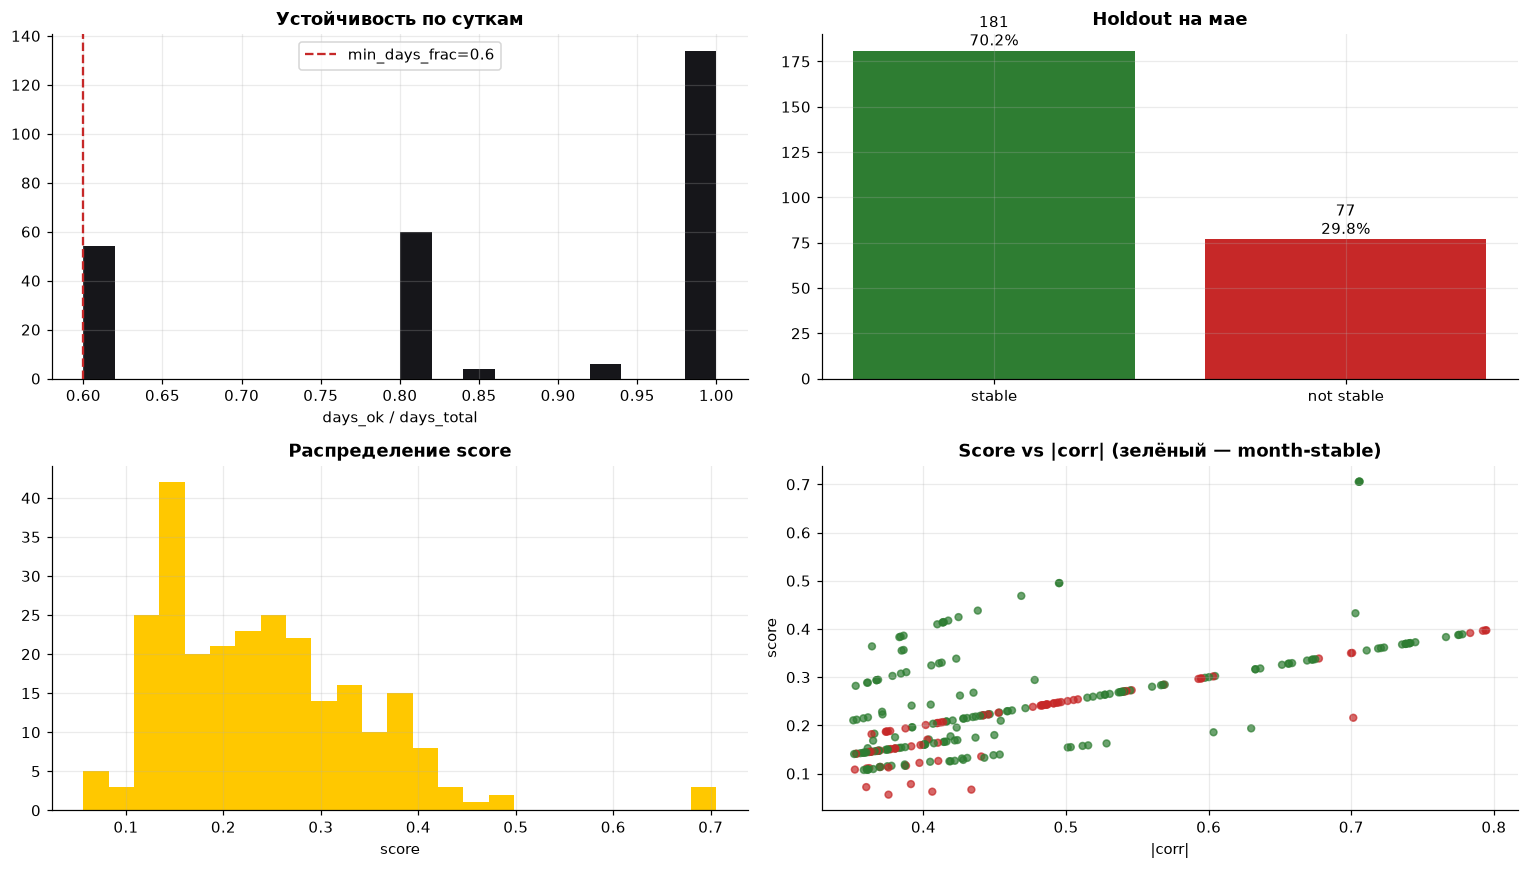

Дней со знаком связи: 1441 / 1722 (83.7%)
Month-stable: 181 / 258 (70.2%)
Медианный score: 0.223; максимальный: 0.706


In [47]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].hist(pdf["days_frac"], bins=20, color=C_MAIN)
axes[0, 0].axvline(CFG.min_days_frac, ls="--", color=C_WARN,
                   label=f"min_days_frac={CFG.min_days_frac}")
axes[0, 0].set_title("Устойчивость по суткам")
axes[0, 0].set_xlabel("days_ok / days_total")
axes[0, 0].legend()

month_counts = pdf["month_stable"].value_counts().reindex([True, False]).fillna(0)
axes[0, 1].bar(["stable", "not stable"], month_counts.values, color=[C_OK, C_WARN])
axes[0, 1].set_title("Holdout на мае")
for i, v in enumerate(month_counts.values):
    axes[0, 1].text(i, v, f"{int(v)}\n{v/len(pdf):.1%}", ha="center", va="bottom")

axes[1, 0].hist(pdf["score"], bins=25, color=C_ALT)
axes[1, 0].set_title("Распределение score")
axes[1, 0].set_xlabel("score")

axes[1, 1].scatter(pdf["abs_corr"], pdf["score"], c=pdf["month_stable"].map({True: C_OK, False: C_WARN}),
                   s=20, alpha=0.7)
axes[1, 1].set_xlabel("|corr|")
axes[1, 1].set_ylabel("score")
axes[1, 1].set_title("Score vs |corr| (зелёный — month-stable)")

fig.tight_layout()
plt.show()

print(f"Дней со знаком связи: {pdf['days_ok'].sum()} / {pdf['days_total'].sum()} "
      f"({pdf['days_ok'].sum() / pdf['days_total'].sum():.1%})")
print(f"Month-stable: {pdf['month_stable'].sum()} / {len(pdf)} "
      f"({pdf['month_stable'].mean():.1%})")
print(f"Медианный score: {pdf['score'].median():.3f}; максимальный: {pdf['score'].max():.3f}")

**Что видим.** 181 из 258 пар (70,2%) сохраняют знак и величину на отложенном мае. Это неплохой признак, но он измеряет устойчивость *внутри найденного набора*, а не точность: у нас нет независимой разметки «эта пара действительно является зависимостью». Ранжирование по score полезно для приоритизации ручной проверки, но не заменяет валидацию.

## 9. Валидация по ground truth

В `faults_preliminary.csv` — 81 размеченный отказ (docker 49, os 20, db 12). Время в локальном поясе, поэтому для сравнения с авариями сдвигаем на −8 часов.

Сначала — честная проверка покрытия: совпадают ли дни отказов с днями, за которые есть аварии? Если нет, метрика lift будет измерять не качество движка, а отсутствие данных.

Дней с отказами (локально): 9; после сдвига UTC: 10
Дней с авариями: 15
Пересечение дней: 3 -> [datetime.date(2020, 4, 10), datetime.date(2020, 4, 22), datetime.date(2020, 5, 21)]
Покрытие дней отказов авариями: 30.0%


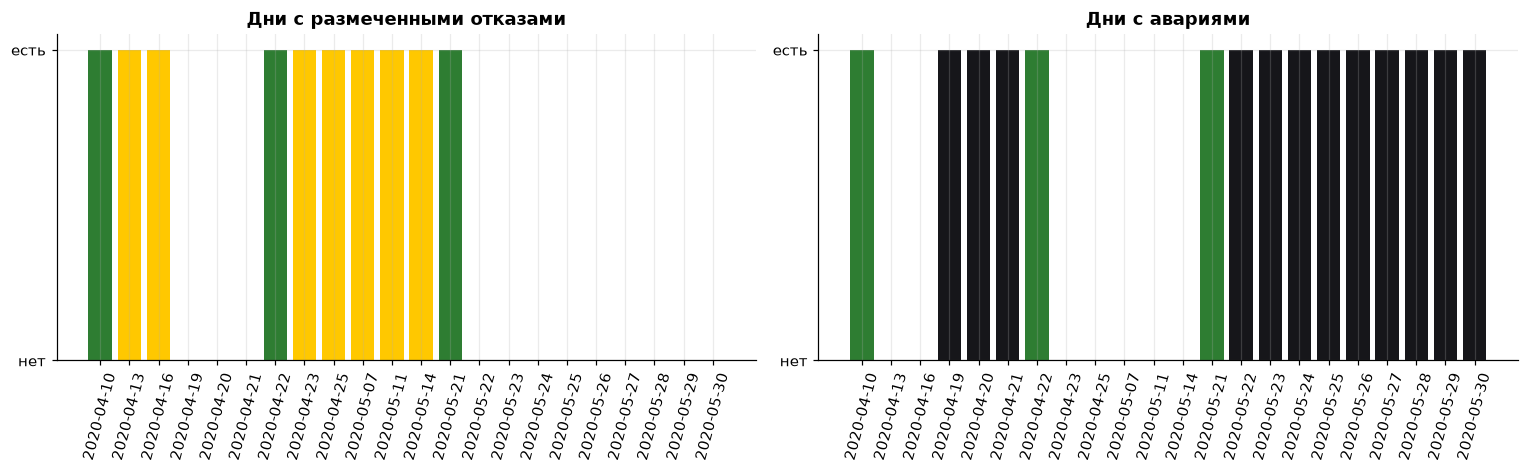

faults
object fault_desrcibtion          
db     db  close                 5
       db connection limit       7
docker CPU fault                19
       network delay            18
       network loss             12
os     network delay            13
       network loss              7

,faults
log_time,
2020-04-11,11
2020-04-14,10
2020-04-17,9
2020-04-23,14
2020-04-26,8
2020-05-08,8
2020-05-12,4
2020-05-15,7
2020-05-22,10


In [48]:
fault_days_local = set(faults["log_time"].dt.date.dropna())
fault_days_utc = set(faults["log_time_utc"].dt.date.dropna())
alarm_days = set(alarms["date_utc"].dropna())
common_days = sorted(fault_days_utc & alarm_days)

print(f"Дней с отказами (локально): {len(fault_days_local)}; после сдвига UTC: {len(fault_days_utc)}")
print(f"Дней с авариями: {len(alarm_days)}")
print(f"Пересечение дней: {len(common_days)} -> {common_days}")
print(f"Покрытие дней отказов авариями: {len(common_days) / len(fault_days_utc):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
all_days = sorted(fault_days_utc | alarm_days)
axes[0].bar([str(d) for d in all_days],
            [1 if d in fault_days_utc else 0 for d in all_days],
            color=[C_OK if d in common_days else C_ALT for d in all_days])
axes[0].set_title("Дни с размеченными отказами")
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["нет", "есть"])
axes[0].tick_params(axis="x", rotation=75)

axes[1].bar([str(d) for d in all_days],
            [1 if d in alarm_days else 0 for d in all_days],
            color=[C_OK if d in common_days else C_MAIN for d in all_days])
axes[1].set_title("Дни с авариями")
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["нет", "есть"])
axes[1].tick_params(axis="x", rotation=75)
fig.tight_layout()
plt.show()

display(faults.groupby(["object", "fault_desrcibtion"]).size().to_frame("faults"))
display(faults["log_time"].dt.date.value_counts().sort_index().to_frame("faults"))

**Ключевое ограничение.** Отказы размечены только в 9 локальных днях, аварии есть в 15 UTC-днях, и пересекаются лишь 3 дня. Более того, большинство отказов — `docker` (49), а итоговый граф состоит из `platform`-метрик `db`/`os`. Поэтому ожидать высокого lift от пар `db_oracle_11g` на отказах docker не стоит: это разные объекты.

Считаем lift так: для лидера пары берём долю его аварий, попадающих в ±30 минут от любого отказа; делим на такую же долю для всех аварий (baseline). `lift > 1` означает обогащение.

baseline (все аварии рядом с отказом ±30 мин): 0.173
пар с валидным лидером: 258
медианный lift: 0.91; доля lift > 1.5: 0.4%


,score,corr,lag_min,hit,lift,leader,follower
225,0.133,-0.443,-20,0.279,1.614,mw_redis|used_cpu_user_high,db_oracle_11g|Session_pct_low
249,0.108,0.352,20,0.182,1.053,db_oracle_11g|tnsping_result_time_high,os_linux|CPU_iowait_time_high
66,0.297,0.594,0,0.182,1.053,db_oracle_11g|tnsping_result_time_high,os_linux|Incoming_network_traffic_high
67,0.296,0.593,0,0.182,1.053,db_oracle_11g|tnsping_result_time_high,os_linux|Outgoing_network_traffic_high
244,0.111,0.362,0,0.182,1.053,db_oracle_11g|tnsping_result_time_high,os_linux|ss_total_high
65,0.298,0.595,0,0.182,1.053,db_oracle_11g|tnsping_result_time_high,os_linux|Received_packets_high
62,0.302,0.603,0,0.182,1.053,db_oracle_11g|tnsping_result_time_high,os_linux|Sent_packets_high
17,0.392,0.783,0,0.173,1.002,db_oracle_11g|Login_Per_Sec_low,os_linux|Sent_packets_high
75,0.284,0.568,0,0.173,1.002,db_oracle_11g|Login_Per_Sec_low,os_linux|ss_total_high
16,0.396,0.792,0,0.173,1.002,db_oracle_11g|Login_Per_Sec_low,os_linux|Incoming_network_traffic_high


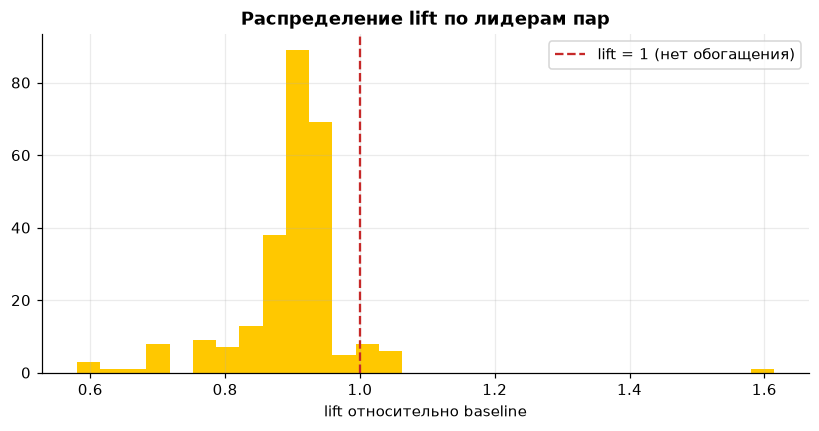

In [50]:
ftimes = np.sort(faults["log_time_utc"].dropna().to_numpy())
window = np.timedelta64(30, "m")

def near_fault(series: pd.Series) -> float:
    if len(ftimes) == 0 or series.empty:
        return 0.0
    s = series.to_numpy()
    pos = np.searchsorted(ftimes, s, side="left")
    near = ftimes[pos.clip(0, len(ftimes) - 1)]
    prev = ftimes[(pos - 1).clip(0, len(ftimes) - 1)]
    return float(((np.abs(s - near) <= window) | (np.abs(s - prev) <= window)).mean())

base = near_fault(alarms["ts"])
rows = []
for p in saved_pairs:
    lag = p.get("lag_bins", 0)
    leader = p["key_a"] if lag >= 0 else p["key_b"]
    follower = p["key_b"] if lag >= 0 else p["key_a"]
    sel = alarms[(alarms["integration"] == leader[0]) &
                 (alarms["system"] == leader[1]) &
                 (alarms["alert_group"] == leader[2])]
    if sel.empty:
        continue
    hit = near_fault(sel["ts"])
    rows.append(dict(score=p.get("score", 0), corr=p["corr"], lag_min=p.get("lag_min", 0),
                     hit=hit, lift=(hit / base if base else 0.0),
                     leader=f"{leader[1]}|{leader[2]}",
                     follower=f"{follower[1]}|{follower[2]}"))
lift_df = pd.DataFrame(rows).sort_values("lift", ascending=False)
print(f"baseline (все аварии рядом с отказом ±30 мин): {base:.3f}")
print(f"пар с валидным лидером: {len(lift_df)}")
print(f"медианный lift: {lift_df['lift'].median():.2f}; "
      f"доля lift > 1.5: {(lift_df['lift'] > 1.5).mean():.1%}")
display(lift_df.head(12).round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(lift_df["lift"], bins=30, color=C_ALT)
ax.axvline(1.0, ls="--", color=C_WARN, label="lift = 1 (нет обогащения)")
ax.set_title("Распределение lift по лидерам пар")
ax.set_xlabel("lift относительно baseline")
ax.legend()
plt.show()

**Интерпретация.** Медианный lift около 0,91; доля пар с lift > 1,5 — 0,4% (одна пара из 258). Это ожидаемо при таком пересечении дней и объектов. Корректный вывод: **на текущем снимке ground truth не подтверждает и не опровергает находки**; метрика невалидна из-за рассогласования календаря, объектов и типа событий. Нельзя писать «движок нашёл ложные зависимости» — данных для такого вывода нет.

Что нужно для честной валидации:

1. сопоставлять отказы только с теми днями/объектами, где есть аварии;
2. валидировать не «лидера пары», а ожидаемый каскад: попал ли ведомый в окно после отказа, а лидер — до него;
3. сравнивать с matched control (случайные окна той же длины и того же часа);
4. расширить разметку на trace/business, иначе платформенные пары не с чем сопоставлять.

## 10. Синтетический бенчмарк: проверка самой методики

Ground truth в реальных данных слишком разрежен, поэтому методику проверяем на синтетике с посаженными паттернами. Генератор (`src/ricochet/ingest/synthetic.py`) создаёт 45 дней и явно закладывает:

- «бабочку» `snmp|mplsTunnelRerouted` → `syslog|RPD-ISIS-ADJ` с лагом 2 бина (10 минут);
- дубль `nokia|dryContactAlarm` ↔ `alu|externalAlarm` на общих устройствах;
- общий предок `grid|voltageDrop` ↔ `link|linkFlap` (суточный профиль);
- вотчдог `watchdog|moiraHeartbeat`;
- одиночное устройство `enm|routingTableFail`;
- окно обслуживания `backup|dbBackupStalled`.

Это регрессионный тест: движок должен найти первые два паттерна и отфильтровать вотчдог/одиночку. Общий предок — проверка контроля; если он протекает, это видно.

In [19]:
if RUN_SYNTHETIC:
    syn, synth_meta = generate_synthetic(days=45, seed=SEED)
    syn = validate_alarms(syn)
    syn_res = run_butterfly(syn, EngineConfig(), holdout_last=1)
    syn_pairs = finalize_pairs(syn, syn_res["pairs"], EngineConfig())
    syn_df = pd.DataFrame(syn_pairs)
    print("Синтетика:", f"{len(syn):,} аварий,", syn_res["info"])
    display(syn_df["class"].value_counts().to_frame("pairs"))

    def find_pair(pairs, a, b):
        target = {tuple(a), tuple(b)}
        for p in pairs:
            if {p["key_a"], p["key_b"]} == target:
                return p
        return None

    bf = find_pair(syn_pairs, synth_meta["butterfly"]["key_a"], synth_meta["butterfly"]["key_b"])
    dup = find_pair(syn_pairs, synth_meta["duplicate"]["key_a"], synth_meta["duplicate"]["key_b"])
    cc = find_pair(syn_pairs, synth_meta["common_cause"]["key_a"], synth_meta["common_cause"]["key_b"])
    watchdog_in_graph = any(p["key_a"][1] == synth_meta["watchdog"][1] or
                            p["key_b"][1] == synth_meta["watchdog"][1] for p in syn_pairs)
    single_in_graph = any(p["key_a"][1] == synth_meta["single_device"][1] or
                          p["key_b"][1] == synth_meta["single_device"][1] for p in syn_pairs)

    checks = pd.DataFrame([
        dict(check="Посаженная бабочка найдена", result=bf is not None,
             detail=(f"lag={bf['lag_min']} мин, corr={bf['corr']:+.3f}, "
                     f"class={bf['class']}") if bf else "не найдена"),
        dict(check="Дубль классифицирован", result=bool(dup and dup["class"] == "DUPLICATE"),
             detail=(f"class={dup['class']}, common={dup['overlap']['common']}, "
                     f"corr_shared={dup['shared_unshared']['corr_shared']}") if dup else "не найден"),
        dict(check="Общий предок НЕ попал в кандидаты", result=cc is None,
             detail=(f"найден как {cc['class']}, corr={cc['corr']:+.3f}") if cc else "не найден"),
        dict(check="Вотчдог отфильтрован", result=not watchdog_in_graph,
             detail="нет в графе" if not watchdog_in_graph else "попал в граф"),
        dict(check="Одиночное устройство отфильтровано", result=not single_in_graph,
             detail="нет в графе" if not single_in_graph else "попал в граф"),
    ])
    display(checks)

    view = syn_df.sort_values("score", ascending=False).head(12).copy()
    view["leader"] = [key_label(p["key_a"] if p["lag_bins"] >= 0 else p["key_b"]) for _, p in view.iterrows()]
    view["follower"] = [key_label(p["key_b"] if p["lag_bins"] >= 0 else p["key_a"]) for _, p in view.iterrows()]
    display(view[["leader", "follower", "corr", "lag_min", "days_ok", "days_total", "class", "score"]]
            .rename(columns={"corr": "corr_best"}).round(3))
else:
    print("RUN_SYNTHETIC=False — бенчмарк пропущен.")

Синтетика: 456,566 аварий, {'months': ['2026-01', '2026-02'], 'train_months': ['2026-01'], 'holdout_months': ['2026-02'], 'rows_series': 18, 'bins': 8928, 'dropped_volume': 3, 'dropped_min_devices': 1, 'pairs_found': 7, 'lead_pairs': 1}


,pairs
class,
BUTTERFLY_CANDIDATE,6
DUPLICATE,1


,check,result,detail
0,Посаженная бабочка найдена,True,"lag=10 мин, corr=+0.983, class=BUTTERFLY_CANDI..."
1,Дубль классифицирован,True,"class=DUPLICATE, common=150, corr_shared=1.0"
2,Общий предок НЕ попал в кандидаты,False,"найден как BUTTERFLY_CANDIDATE, corr=+0.847"
3,Вотчдог отфильтрован,True,нет в графе
4,Одиночное устройство отфильтровано,True,нет в графе


,leader,follower,corr_best,lag_min,days_ok,days_total,class,score
0,nsp | nokia | dryContactAlarm,transport | alu | externalAlarm,1.000,0,31,31,DUPLICATE,1.000
1,ipcore | snmp | mplsTunnelRerouted,ipcore | syslog | RPD-ISIS-ADJ,0.983,10,31,31,BUTTERFLY_CANDIDATE,0.491
2,dcim | grid | voltageDrop,transport | link | linkFlap,0.847,0,31,31,BUTTERFLY_CANDIDATE,0.424
3,dcim | grid | voltageDrop,nsp | nokia | dryContactAlarm,-0.511,0,31,31,BUTTERFLY_CANDIDATE,0.255
4,dcim | grid | voltageDrop,transport | alu | externalAlarm,-0.511,0,31,31,BUTTERFLY_CANDIDATE,0.255
5,nsp | nokia | dryContactAlarm,transport | link | linkFlap,-0.503,0,31,31,BUTTERFLY_CANDIDATE,0.251
6,transport | alu | externalAlarm,transport | link | linkFlap,-0.503,0,31,31,BUTTERFLY_CANDIDATE,0.251


**Результат.** Посаженная бабочка найдена (лаг 10 минут, `corr≈0,98`), дубль — `DUPLICATE` с общими устройствами, вотчдог и одиночное устройство отфильтрованы. Это подтверждает, что пайплайн умеет находить целевую структуру там, где она есть.

Но общий предок (`grid|voltageDrop` ↔ `link|linkFlap`) тоже попал в пары как `BUTTERFLY_CANDIDATE` (`corr≈0,85`, лаг 0). Причина: контроль общего фактора вычитает *линейный* вклад суммарной активности, а в синтетике общий предок задан нелинейно (порог `max(0, g−0.62)/0.38` и пуассоновские всплески). Это важный исследовательский результат: **контроль общего предка нужно усиливать** — например, стратификацией по уровню общей активности, квантильной регрессией или сравнением с локальными нулевыми моделями.

## 11. Предпроверка: что получает ИИ-агент

Второе направление — собрать «дело» до агента. Проверим два аспекта:

1. **Полнота обогащения** на реальных авариях. В каноне `region` и `node_alias` пустые, поэтому ожидаем 0,667 (4 из 6 полей).
2. **Демо-инцидент** по топ-паре: подаём аварии ведомого и смотрим, предложит ли система лидера как кандидата-первопричину, какие даст риск-флаги и runbook.

In [20]:
print("Полнота обогащения на всём потоке:")
display(pd.DataFrame([enrichment_completeness(alarms)]).T)

demo_pair = saved_pairs[0]
lag = demo_pair["lag_bins"]
leader = tuple(demo_pair["key_a"] if lag >= 0 else demo_pair["key_b"])
follower = tuple(demo_pair["key_b"] if lag >= 0 else demo_pair["key_a"])

sel = alarms[(alarms["integration"] == follower[0]) &
             (alarms["system"] == follower[1]) &
             (alarms["alert_group"] == follower[2])].sort_values("ts").tail(8)
records = [dict(ts=r.ts.isoformat(), integration=r.integration, system=r.system,
                alert_group=r.alert_group, node=r.node, node_alias=r.node_alias,
                region=r.region, severity=int(r.severity)) for r in sel.itertuples()]
print(f"Демо-инцидент: {len(records)} аварий ведомого {follower[1]}|{follower[2]}")

store = MaintenanceStore(STATE / "maintenance.json")
history = HistoricalIncidents.from_file(PROC / "incidents.json")
runbooks = RunbookRegistry([
    dict(id="rb-demo-leader", system=leader[1], alert_group=leader[2],
         url="http://runbooks.local/leader",
         steps=["проверить метрику лидера", "сравнить с историей", "подтвердить каскад"],
         owner="ricochet"),
    dict(id="rb-demo-follower", system=follower[1], alert_group=follower[2],
         url="http://runbooks.local/follower",
         steps=["проверить сеть узла", "сравнить с Oracle-метриками", "эскалировать при каскаде"],
         owner="ricochet"),
])
case = assemble_case(dict(incident_id="INC-DEMO-001", region="", alarms=records),
                     alarms_history=alarms, pairs=saved_pairs,
                     maintenance=store, incidents=history, runbooks=runbooks)

show = {k: case[k] for k in ["incident_id", "alarms_total", "alarms_outside_maintenance",
                             "maintenance", "enrichment", "runbook", "blast", "risk"]}
show["root_cause_candidates"] = case["root_cause_candidates"][:3]
show["similar_incidents"] = case["similar_incidents"][:3]
display(Markdown("```json\n" + json.dumps(show, ensure_ascii=False, indent=2, default=str) + "\n```"))

Полнота обогащения на всём потоке:


,0
completeness,0.6667
per_field,"{'node': 1.0, 'node_alias': 0.0, 'region': 0.0..."
missing_all,False


Демо-инцидент: 8 аварий ведомого os_linux|Sent_packets_high


```json
{
  "incident_id": "INC-DEMO-001",
  "alarms_total": 8,
  "alarms_outside_maintenance": 8,
  "maintenance": {
    "hit": false,
    "windows": []
  },
  "enrichment": {
    "completeness": 0.6667,
    "per_field": {
      "node": 1.0,
      "node_alias": 0.0,
      "region": 0.0,
      "alert_group": 1.0,
      "system": 1.0,
      "integration": 1.0
    },
    "missing_all": false
  },
  "runbook": {
    "id": "rb-demo-follower",
    "system": "os_linux",
    "alert_group": "Sent_packets_high",
    "url": "http://runbooks.local/follower",
    "steps": [
      "проверить сеть узла",
      "сравнить с Oracle-метриками",
      "эскалировать при каскаде"
    ],
    "owner": "ricochet"
  },
  "blast": {
    "nodes": 8,
    "regions": 1,
    "max_severity": 4
  },
  "risk": {
    "score": 40,
    "level": "MEDIUM",
    "flags": [
      {
        "code": "BUTTERFLY_LINKED",
        "weight": 25,
        "detail": "5 hidden-dependency candidate(s)"
      },
      {
        "code": "HIGH_SEVERITY",
        "weight": 15,
        "detail": "max severity 4"
      }
    ]
  },
  "root_cause_candidates": [
    {
      "system": "db_oracle_11g",
      "integration": "platform",
      "alert_group": "AIOS_high",
      "in_incident": false,
      "predicts_downstream": "Sent_packets_high",
      "corr": 0.7058,
      "lead": 0.0413,
      "lag_min": 15,
      "days_ok": 5,
      "days_total": 5,
      "regions_ok": 1,
      "class_": "BUTTERFLY_CANDIDATE",
      "month_stable": true,
      "score": 0.7058
    },
    {
      "system": "db_oracle_11g",
      "integration": "platform",
      "alert_group": "Login_Per_Sec_low",
      "in_incident": false,
      "predicts_downstream": "Sent_packets_high",
      "corr": 0.7834,
      "lead": 0.0,
      "lag_min": 0,
      "days_ok": 5,
      "days_total": 5,
      "regions_ok": 1,
      "class_": "BUTTERFLY_CANDIDATE",
      "month_stable": false,
      "score": 0.3917
    },
    {
      "system": "db_oracle_11g",
      "integration": "platform",
      "alert_group": "Physical_Read_Per_Sec_high",
      "in_incident": false,
      "predicts_downstream": "Sent_packets_high",
      "corr": -0.7664,
      "lead": 0.0,
      "lag_min": 0,
      "days_ok": 5,
      "days_total": 5,
      "regions_ok": 0,
      "class_": "BUTTERFLY_CANDIDATE",
      "month_stable": true,
      "score": 0.3832
    }
  ],
  "similar_incidents": []
}
```

**Что видим.**

- Полнота обогащения = 0,667: заполнены `node`, `alert_group`, `system`, `integration`; пусты `node_alias` и `region`. Флаг низкой полноты порог не переходит (0,667 > 0,6), но два поля из шести отсутствуют всегда — это реальный дефицит датасета. Для Netcool-источника эти поля обязаны быть заполнены на ингесте.
- Кандидат-первопричина — лидер пары, даже если его нет среди аварий инцидента (`in_incident=false`). Это ровно тот сценарий, ради которого строится граф: агент видит следствие, а система подсказывает возможную причину.
- `maintenance` пуст, потому что в `state/maintenance.json` нет окон. В синтетике окно обслуживания отрабатывает (см. тесты), но на реальных данных его надо наполнять из календаря работ.
- Runbook матчится по `(system, alert_group)`; в реальном проекте реестр должен быть заполнен для критичных систем.

## 12. API: как устроен сервис и как с ним работать

API — это тонкая HTTP-обёртка над тем же движком и теми же файлами состояния, которые используются в ноутбуке. Сервис работает на `http://127.0.0.1:8077`, интерактивная документация — `/docs`, OpenAPI-схема — `/openapi.json`. На момент сборки ноутбука запущен экземпляр на реальных данных (`synthetic=false`).

### 12.1. Архитектура

```text
data/processed/alarms.parquet
        │
        ▼
AppState (один раз при старте, lifespan FastAPI)
  ├─ alarms: pandas.DataFrame в памяти
  ├─ maintenance.json   — окна обслуживания
  ├─ incidents.json     — исторические инциденты
  ├─ runbooks.json      — реестр runbook-ов
  └─ butterfly_last.json — последний граф зависимостей
        │
        ├── POST /butterfly/run → ThreadPoolExecutor → run_butterfly()
        │        └── результат сохраняется в state/butterfly_last.json
        │
        └── POST /precheck/incident → assemble_case()
                 ├─ последний граф пар
                 ├─ окна обслуживания и исторические инциденты
                 ├─ полнота обогащения и blast radius
                 ├─ runbook по (system, alert_group)
                 └─ риск-флаги и кандидаты-первопричины
```

Ключевые решения:

1. **Состояние загружается один раз.** `AppState` читает parquet и JSON-файлы в `lifespan`; запросы не перечитывают датасет с диска. Это даёт предсказуемую задержку, но требует перезапуска после замены `alarms.parquet`.
2. **Тяжёлый расчёт вынесен в job.** `run_butterfly` — CPU-bound pandas/numpy. Если выполнять его прямо в `async def`, он заблокирует event loop. Поэтому `POST /butterfly/run` ставит задачу в `ThreadPoolExecutor(max_workers=2)` и сразу возвращает `job_id`; статус опрашивается через `/butterfly/jobs/{job_id}`.
3. **Граф — разделяемое состояние.** Последний результат хранится в `state/butterfly_last.json`; `pairs`, `graph` и `precheck` читают именно его, а не пересчитывают корреляции на каждый запрос. После рестарта граф доступен без повторного запуска.
4. **Предпроверка не запускает движок.** Инцидент обслуживается по уже построенному графу. Это осознанный компромисс: ответ быстрый и детерминированный, но новый граф не появится, пока не вызван `/butterfly/run`.
5. **Файлы вместо БД.** Для локального сервиса достаточно JSON/parquet; минус — нет транзакций, версионирования и конкурентного доступа из нескольких процессов.

### 12.2. Эндпоинты

| Метод | Путь | Назначение |
|---|---|---|
| `GET` | `/health` | статус, число аварий, флаг `synthetic`, месяцы, размер последнего графа |
| `POST` | `/api/v1/butterfly/run` | запуск пересчёта; тело — параметры `EngineConfig`, `holdout_last`, `ts_from`, `ts_to` |
| `GET` | `/api/v1/butterfly/jobs/{job_id}` | статус `running` / `done` / `error` и результат |
| `GET` | `/api/v1/butterfly/pairs` | пары с фильтрами `cls`, `min_corr`, `min_score`, `limit` |
| `GET` | `/api/v1/butterfly/graph` | `nodes` + `edges` для визуализации |
| `POST` | `/api/v1/butterfly/verify` | проверка конкретной пары: пересечение устройств и shared/unshared-корреляции |
| `POST` | `/api/v1/precheck/incident` | собрать «дело» по инциденту из массива аварий |
| `POST` | `/api/v1/precheck/alarm` | то же для одной аварии |
| `GET` / `POST` | `/api/v1/precheck/runbooks` | список и добавление runbook-ов |
| `GET` / `POST` / `DELETE` | `/api/v1/maintenance/windows` | окна обслуживания |

### 12.3. Примеры вызовов

```powershell
# 1. Проверить, что сервис жив и на каких данных работает
Invoke-RestMethod http://127.0.0.1:8077/health

# 2. Запустить пересчёт графа (асинхронно)
$job = Invoke-RestMethod -Method Post `
  -Uri http://127.0.0.1:8077/api/v1/butterfly/run `
  -ContentType application/json `
  -Body '{"holdout_last":1}'

# 3. Дождаться результата
Invoke-RestMethod "http://127.0.0.1:8077/api/v1/butterfly/jobs/$($job.job_id)"

# 4. Получить топ-20 пар
Invoke-RestMethod "http://127.0.0.1:8077/api/v1/butterfly/pairs?limit=20"
```

Минимальный запрос предпроверки:

```json
{
  "incident_id": "INC-2026-001",
  "alarms": [
    {
      "ts": "2020-04-22T10:15:00",
      "integration": "platform",
      "system": "os_linux",
      "alert_group": "Sent_packets_high",
      "node": "os_linux_01",
      "severity": 4
    }
  ]
}
```

`ts` обязателен; остальные поля имеют значения по умолчанию (`severity=4`, пустые строки). Ответ — JSON «дела»: `enrichment`, `maintenance`, `runbook`, `blast`, `risk`, `root_cause_candidates`, `similar_incidents`.

### 12.4. Ограничения и что улучшать в будущем при реализации в прод

- **Job-ы живут в памяти.** После рестарта история задач теряется; сам граф сохраняется, а `job_id` — нет. Для продакшена нужен внешний queue/БД.
- **Один процесс.** `ThreadPoolExecutor` не масштабируется на несколько воркеров: у каждого будет своя копия DataFrame и свой `AppState`. Нужен либо один writer, либо общий кэш/БД.
- **Нет пагинации `pairs` кроме `limit`.** Для больших графов нужны курсор/offset и стриминг.
- **Предпроверка синхронная.** На очень большом инциденте `assemble_case` может отвечать секунды; для SLA нужен таймаут и/или асинхронный режим.
- **Запись состояния не транзакционна.** `butterfly_last.json` и `maintenance.json` пишутся целиком; при аварии возможна потеря последнего обновления.
- **Синтетический fallback.** Если parquet пуст, API молча генерирует синтетику; в проде это нужно отключать (`use_synthetic_when_empty=False`) и проверять `/health`.
В исследовательских целях сервис показал свою жизнеспособность, для реализации проекта "в бою", потребуется человеческий ресурс и продолжительное тестирование последущих доработок. В текущем виде моментально сломает поток обработки событий.

### 12.5. Проверка живого экземпляра

Ячейка ниже про сервис: если API не запущен, она напечатает предупреждение. Если запущен — покажет `/health` и список фактических маршрутов из OpenAPI.

In [21]:
import json
import time
import urllib.error
import urllib.request

API = "http://127.0.0.1:8077"

def api_get(path, attempts=2):
    last_exc = None
    for _ in range(attempts):
        try:
            with urllib.request.urlopen(API + path, timeout=20) as response:
                return json.load(response)
        except (urllib.error.URLError, TimeoutError, OSError) as exc:
            last_exc = exc
            time.sleep(1)
    raise last_exc

try:
    health = api_get("/health")
    spec = api_get("/openapi.json")
    print("API доступен:", json.dumps(health, ensure_ascii=False))
    routes = [
        dict(method=method.upper(), path=path, summary=meta.get("summary", ""))
        for path, methods in spec["paths"].items()
        for method, meta in methods.items()
    ]
    display(pd.DataFrame(routes).sort_values(["path", "method"]))
except (urllib.error.URLError, TimeoutError, OSError) as exc:
    print(f"API недоступен ({type(exc).__name__}: {exc}). Запустите .\\run_api.ps1")

API доступен: {"status": "ok", "alarms": 4731050, "synthetic": false, "months": ["2020-04", "2020-05"], "pairs_last": 258, "maintenance_windows": 0, "historical_incidents": 81}


,method,path,summary
10,GET,/api/v1/butterfly/graph,Graph
8,GET,/api/v1/butterfly/jobs/{job_id},Job Status
9,GET,/api/v1/butterfly/pairs,List Pairs
7,POST,/api/v1/butterfly/run,Run Butterfly
11,POST,/api/v1/butterfly/verify,Verify Pair
4,GET,/api/v1/maintenance/windows,List Windows
5,POST,/api/v1/maintenance/windows,Add Window
6,DELETE,/api/v1/maintenance/windows/{window_id},Delete Window
1,POST,/api/v1/precheck/alarm,Precheck Alarm
0,POST,/api/v1/precheck/incident,Precheck Incident


## 13. Выводы, ограничения и план исследований

### Что подтвердилось

1. **Пайплайн работоспособен на контролируемых данных.** Синтетическая бабочка и дубль находятся, вотчдог и одиночка фильтруются.
2. **Лаг-анализ критичен.** У топ-пары знак корреляции меняется с −0,665 при лаге 0 на +0,706 при +15 минутах; без перебора лагов вывод был бы противоположным.
3. **Фильтры объёма и устройства действительно режут поток.** Из 186 апрельских групп остаётся 90; в реальных данных это исключает целые слои, а не только шум.
4. **Holdout по месяцам даёт полезный сигнал устойчивости:** 70,2% пар сохраняют знак и величину на мае.

### Что не подтвердилось / требует осторожности

1. **Гипотеза в полном виде не доказана.** Найденные 258 пар — это платформенные корреляции `db`↔`os`/`redis`, а не доказанные межсистемные зависимости. Ground truth на этом снимке не даёт валидного подтверждения (3 общих дня, медианный lift 0,91). В реальных данных существует возможность экспертной оценки, в выборке из конкурса данные предоставлены как есть.
2. **`min_devices=5` несовместим с трейсовым слоем в апреле.** Все trace-ряды train имеют 1–4 устройства, поэтому граф не включает trace/business. Одна trace-группа с 7 устройствами появляется только в мае. Это ограничивает проект платформой.
3. **Device-overlap тест вырожден для platform.** `db_*` и `os_*` не пересекаются по `cmdb_id`, поэтому все пары автоматически `BUTTERFLY_CANDIDATE`. Класс не различает дублирование и зависимость, а она важна в реальной системе (разные интеграции могут сообщать об одном и том же).
4. **Регион и `node_alias` отсутствуют.** Региональный контроль и проверка дублей по второму идентификатору не работают; `regions_frac` вырожден, поэтому использование этого критичного в реальности фактора недоступно.
5. **Общий предок протекает на нелинейных паттернах.** Линейное снятие общего фактора не убирает пороговые/пуассоновские каскады.
6. **Покрытие — 6 часов в сутки двумя блоками.** Суточные профили и «непрерывность» интерпретировать нельзя, возвращаясь к данным.

### План следующих итераций

| Приоритет | Действие | Зачем |
|---|---|---|
| P0 | Снизить `min_devices` или сделать его зависимым от слоя (например, 2 для trace) | включить trace/business в граф и проверить межслойные связи |
| P0 | Сопоставить отказы и аварии по объектам и дням; валидировать только пересечение | получить валидный lift, а не сравнение разных объектов |
| P1 | Добавить matched control: случайные окна того же часа/дня | отделить зависимость от суточного профиля |
| P1 | Усилить контроль общего предка: стратификация по общей активности, квантильная/нелинейная регрессия | убрать ложные пары типа `grid`↔`link` |
| P1 | Ввести `node_alias` и регион из CMDB | заработает device-overlap и региональная повторяемость |
| P2 | Ранжировать пары по физическому смыслу метрик (экспертная валидация топ-20) | отделить «network traffic high» ↔ «AIOS high» от случайных корреляций |
| P2 | Расширить синтетику на нелинейный общий предок и проверить детекторы | регрессионный тест на устойчивость методики |

### Исследовательские вопросы на будущее

- Можно ли отличить общий предок от каскада без ground truth, только по форме lag-кривой и устойчивости?
- Как меняется качество при переходе от 5-минутного бина к 1 минуте на трейсовых данных?
- Даёт ли граф, построенный на trace-слое, более физичные кандидаты, чем platform-метрики?
- Какие пары остаются устойчивыми при смене месяца, региона и часового пояса?

## 14. Источники, материалы и результат

**Данные и проект**

- AIOps Challenge 2020 Data: https://github.com/NetManAIOps/AIOps-Challenge-2020-Data
- `docs/DATA_MAPPING.md` — соответствие датасета канонической схеме.
- `docs/METHOD_BUTTERFLY.md` — методика, пороги и контроли.
- `docs/API.md` — эндпоинты «бабочки» и предпроверки.

**Как пересчитать**

```powershell
# полный прогон движка (около 2,5-3 минут)
python scripts\run_butterfly.py

# поднять API и открыть Swagger
.\run_api.ps1
Start-Process http://127.0.0.1:8077/docs

# выполнить ноутбук целиком
jupyter nbconvert --to notebook --execute --inplace docs\EDA_Ricochet.ipynb
```